# Stage 5 — Final Held-Out Evaluation

**Study:** Mask-Aware Temporal World Modeling for Robust Industrial Condition Monitoring (IAI 2027)

**This notebook only evaluates.** It never trains:

- The nine frozen Stage 3/4 checkpoints (`model_{a,b,c}_best_seed{11,22,33}.pt`) are loaded and put in evaluation mode.
- Predictions run under `torch.inference_mode()`.
- No optimizer is constructed, and parameter fingerprints before and after scoring show the weights are unchanged.

Every evaluation rule was frozen in `configs/stage5.yaml` before any test prediction, and its SHA-256 hash is recorded in `results/stage5/protocol_manifest.json`. Thresholds come from **clean validation** data only. The models are scored once; all predictions and per-window scores are saved, and every table, figure and statistic below is computed from the saved files.

**Final scientific question.** Does the held-out test period confirm that corruption augmentation reduces degradation and dropout-induced alerts? And does an explicit availability mask add a consistent, practically meaningful benefit beyond augmentation?

| Section | Contents |
|---|---|
| 9.1 | Freeze the protocol and verify test isolation |
| 9.2 | Checkpoint, data and preprocessing integrity |
| 9.3 | Fixed paired test dropout schedules |
| 9.4 | Evaluation-only scoring and final robustness comparison |
| 9.5 | Clean-validation thresholds and alert stability |
| 9.6 | Machine-level uncertainty and seed consistency |
| 9.7 | Failure-event analysis (exploratory) |
| 9.8 | Sensitivity, diagnostics and limitations |
| 9.9 | Figures, tables, evidence ledger and acceptance gate |

| File | Contents |
|---|---|
| `configs/stage5.yaml` | frozen Stage 5 protocol, including the claim rules of the evidence ledger |
| `src/evaluation/final.py` | protocol freezing, hashes, `evaluate_only` (eval mode + inference mode) |
| `src/evaluation/failure_events.py` | events, episodes, causal alarm matching, incidents |
| `src/evaluation/robustness.py` | Stage 4 metrics, alerts, machine bootstrap (reused) |
| `tests/test_stage5_protocol.py` | protocol tests (run in 9.2) |

In [1]:
# =============================================================================
# Setup
# =============================================================================
import inspect
import json
import pickle
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

%load_ext autoreload
%autoreload 2

PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate the project root (no pyproject.toml found).")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data import TIME_COLUMNS, WindowTimeline, load_azure_dataset, make_generator, policy_inputs, scenario_schedule
from src.evaluation import (affected_windows, alarm_incidents, alert_rate, alert_threshold, bootstrap_weights,
                            chance_recall, credit_windows, detect_episodes, evaluate_only, failure_episodes,
                            failure_events, file_sha256, freeze_protocol, interval, machine_sums, paired_metrics,
                            proxy_normal_windows, state_fingerprint, tensor_sha256, weighted_ratio, window_scores)
from src.training import load_checkpoint, load_configs, select_device

config, S4 = load_configs(PROJECT_ROOT)
S5_PATH = PROJECT_ROOT / "configs" / "stage5.yaml"
S5 = yaml.safe_load(S5_PATH.read_text(encoding="utf-8"))

MODELS, SEEDS = S5["models"]["keys"], S5["models"]["seeds"]
INPUT_MASK = S5["models"]["input_mask"]
EVAL_PARTITION, CAL_PARTITION = S5["data"]["evaluation_partition"], S5["data"]["calibration_partition"]
SCENARIOS, INDEPENDENT, HELD_OUT = (S5["corruption"]["scenarios"], S5["corruption"]["independent"],
                                    S5["corruption"]["held_out_patterns"])
SCENARIO_SPECS = {n: S4["evaluation"]["scenarios"][n] for n in SCENARIOS}
SEVERITY = {n: SCENARIO_SPECS[n]["rate"] for n in ["clean", *INDEPENDENT]}
PCT = S5["alerts"]["percentile"]
WINDOWS_PER_DAY = 4  # 6 h stride: 4 windows = 1 machine-day of monitored target blocks
DEVICE = select_device(config["training"]["device"])

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
RESULTS_DIR = PROJECT_ROOT / S5["outputs"]["results_dir"]
FIGURES_DIR = PROJECT_ROOT / S5["outputs"]["figures_dir"]
PRED_DIR = PROJECT_ROOT / S5["outputs"]["predictions_dir"]
SCORES_PATH = PROJECT_ROOT / S5["outputs"]["per_window_scores"]
DRY_RUN = False  # True only when debugging the notebook on validation data (outputs then go elsewhere)
RESCORE = False  # False: reuse the saved predictions and scores if they exist (no model is run again)

MODEL_COLORS = {"A": "#2a78d6", "B": "#eb6834", "C": "#1baf7a"}
MODEL_MARKERS = {"A": "o", "B": "s", "C": "^"}
MODEL_LABELS = {"A": "A  clean training", "B": "B  augmented, all-ones mask", "C": "C  augmented, mask-aware"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "grid.linewidth": 0.5})


def show_location(obj):
    # print where a function or class imported from src/ is defined
    path = Path(inspect.getsourcefile(obj)).relative_to(PROJECT_ROOT).as_posix()
    print(f"Using {obj.__name__} from {path}, line {inspect.getsourcelines(obj)[1]}")


def rel(path):
    try:
        return Path(path).relative_to(PROJECT_ROOT).as_posix()
    except ValueError:
        return str(path)


def mean_std(values):
    values = [float(v) for v in values]
    return {"mean": float(np.mean(values)), "std": float(np.std(values, ddof=1)) if len(values) > 1 else 0.0}


def pm(values, fmt="{:.3f}"):
    ms = mean_std(values)
    return f"{fmt.format(ms['mean'])} ± {fmt.format(ms['std'])}"


def save_json(obj, path):
    Path(path).write_text(json.dumps(obj, indent=2, default=str), encoding="utf-8")


print(f"Evaluation partition: {EVAL_PARTITION}; calibration partition: {CAL_PARTITION}; device {DEVICE}")
print(f"Models {MODELS} x seeds {SEEDS}; scenarios {SCENARIOS}")

Evaluation partition: test; calibration partition: val; device cpu
Models ['A', 'B', 'C'] x seeds [11, 22, 33]; scenarios ['clean', 'independent_10', 'independent_20', 'independent_40', 'burst_6h', 'burst_12h', 'outage']


## 9.1 Freeze the protocol and verify test isolation

`freeze_protocol` hashes `configs/stage5.yaml` and writes `results/stage5/protocol_manifest.json`. It refuses to freeze if per-window test scores or saved predictions already exist. On later runs it only **verifies** that the protocol is unchanged; a deliberate correction must be logged as an amendment, with the date and whether test results had been seen.

The cell then checks that the frozen settings are the Stage 4 settings (scenarios, mask policies, seeds, selected epochs) and that nothing before Stage 5 used the test partition for training, selection or calibration.

**Caveat.** Stage 1 included exploratory, failure-centred plots over the whole period. The test period was therefore not unseen in every exploratory sense. What matters here is that no model, rule or threshold is chosen from test outcomes.

In [2]:
show_location(freeze_protocol)
MANIFEST_PATH = RESULTS_DIR / "protocol_manifest.json"
S5_SHA = file_sha256(S5_PATH)
if DRY_RUN:
    manifest, created = {"sha256": S5_SHA, "note": "dry run on validation data: protocol not frozen"}, False
else:
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    manifest, created = freeze_protocol(
        S5_PATH, MANIFEST_PATH, guard_paths=[SCORES_PATH, PRED_DIR],
        extra={"base_config_sha256": file_sha256(PROJECT_ROOT / "configs" / "base.yaml"),
               "stage4_config_sha256": file_sha256(PROJECT_ROOT / "configs" / "stage4.yaml"),
               "evaluation_partition": EVAL_PARTITION, "calibration_partition": CAL_PARTITION,
               "caveat": "Stage 1 exploratory plots covered the full period, including test."})
print(f"Protocol {rel(S5_PATH)}: sha256 {S5_SHA}")
print("Frozen now (first run)." if created else f"Verified against the manifest frozen at {manifest.get('frozen_at', '-')}.")

stage4_summary = json.loads((PROJECT_ROOT / "results" / "stage4_summary.json").read_text(encoding="utf-8"))
isolation = {
    "scenario definitions = Stage 4 (configs/stage4.yaml)": all(SCENARIO_SPECS[n] == S4["evaluation"]["scenarios"][n] for n in SCENARIOS),
    "mask policies = Stage 4": all(INPUT_MASK[m] == S4["models"][m]["input_mask"] for m in MODELS),
    "seeds = base config seeds": SEEDS == config["training"]["random_seeds"],
    "expected selected epochs = Stage 4 summary": all(
        S5["models"]["expected_selected_epochs"][m][i] == stage4_summary["training"][f"{m}_seed{s}"]["selected_epoch"]
        for m in MODELS for i, s in enumerate(SEEDS)),
    "Stage 3/4 never used the test partition": stage4_summary["data"]["test_partition_used"] is False,
    "thresholds from the validation partition": CAL_PARTITION == "val",
    "test scenario seed differs from validation seed": S5["corruption"]["scenario_seed"] != S4["evaluation"]["scenario_seed"],
}
display(pd.Series(isolation, name="check").to_frame())
assert all(isolation.values())

Using freeze_protocol from src/evaluation/final.py, line 39
Protocol configs/stage5.yaml: sha256 46c105e49c34108bb1d43b0fbfece4648d7281fd720f12215f1b3c097620fbe5
Verified against the manifest frozen at 2026-10-27T15:22:53+00:00.


,check
scenario definitions = Stage 4 (configs/stage4.yaml),True
mask policies = Stage 4,True
seeds = base config seeds,True
expected selected epochs = Stage 4 summary,True
Stage 3/4 never used the test partition,True
thresholds from the validation partition,True
test scenario seed differs from validation seed,True


## 9.2 Checkpoint, data and preprocessing integrity

- **Checkpoints.** All nine are loaded with the existing `load_checkpoint` and checked for: identity, file hash, selected epoch, parameter count, finite weights and mask policy. A fingerprint of their parameters is taken now and compared again after scoring.
- **Data.** Window shapes and timing, partition boundaries and the absence of label fields are checked on the test windows.
- **Scaler provenance.** The scaler must have been fitted on training rows only. Sample test windows are recomputed from the raw telemetry with that scaler.
- **Regression check.** The clean-validation outputs of every checkpoint are recomputed and compared with the values recorded in Stage 4.

In [3]:
show_location(load_checkpoint)
show_location(state_fingerprint)
models, ckpts, FINGERPRINT, rows = {}, {}, {}, []
for m in MODELS:
    for i, s in enumerate(SEEDS):
        path = PROJECT_ROOT / S5["models"]["checkpoint"].format(key=m.lower(), seed=s)
        model, ck = load_checkpoint(path, DEVICE)
        model.eval()
        models[(m, s)], ckpts[(m, s)] = model, ck
        FINGERPRINT[(m, s)] = state_fingerprint(model)
        cfg = ck["config"]
        rows.append({"model": m, "seed": s, "checkpoint": rel(path), "file_sha256": file_sha256(path),
                     "stored_model": ck["model"].split(":")[0], "stored_seed": ck["seed"], "selected_epoch": ck["epoch"],
                     "expected_epoch": S5["models"]["expected_selected_epochs"][m][i],
                     "parameters": sum(p.numel() for p in model.parameters()),
                     "latent_dim": cfg["model"]["latent_dim"], "context_length": cfg["data"]["context_length"],
                     "prediction_horizon": cfg["data"]["prediction_horizon"],
                     "weights_finite": all(torch.isfinite(v).all().item() for v in model.state_dict().values()),
                     "stored_input_mask": ck.get("input_mask", "ones"), "protocol_input_mask": INPUT_MASK[m],
                     "selection_partition": "val", "selection_rule": ck["selection"],
                     "eval_mode": not model.training, "parameter_fingerprint": FINGERPRINT[(m, s)]})
checkpoint_manifest = pd.DataFrame(rows)
checkpoint_manifest.to_csv(RESULTS_DIR / "checkpoint_manifest.csv", index=False)
display(checkpoint_manifest.drop(columns=["file_sha256", "parameter_fingerprint", "selection_rule"]))

ckpt_checks = {
    "9 checkpoints, unique paths and hashes": len(checkpoint_manifest) == 9 and checkpoint_manifest["checkpoint"].nunique() == 9
                                              and checkpoint_manifest["file_sha256"].nunique() == 9,
    "model key and seed match the file": bool((checkpoint_manifest["stored_model"] == "Model " + checkpoint_manifest["model"]).all()
                                              and (checkpoint_manifest["stored_seed"] == checkpoint_manifest["seed"]).all()),
    "selected epochs as recorded in Stage 4": bool((checkpoint_manifest["selected_epoch"] == checkpoint_manifest["expected_epoch"]).all()),
    f"{S5['models']['expected_parameters']:,} parameters, latent 32, history 4, horizon 1": bool(
        (checkpoint_manifest["parameters"] == S5["models"]["expected_parameters"]).all()
        and (checkpoint_manifest["latent_dim"] == 32).all() and (checkpoint_manifest["context_length"] == 4).all()
        and (checkpoint_manifest["prediction_horizon"] == 1).all()),
    "all weights finite": bool(checkpoint_manifest["weights_finite"].all()),
    "mask policy matches model identity (A/B ones, C mask)": bool((checkpoint_manifest["stored_input_mask"] == checkpoint_manifest["protocol_input_mask"]).all()),
    "all models in evaluation mode": bool(checkpoint_manifest["eval_mode"].all()),
}
display(pd.Series(ckpt_checks, name="check").to_frame())
assert all(ckpt_checks.values())

Using load_checkpoint from src/training/trainer.py, line 236
Using state_fingerprint from src/evaluation/final.py, line 30


,model,seed,checkpoint,stored_model,stored_seed,selected_epoch,expected_epoch,parameters,latent_dim,context_length,prediction_horizon,weights_finite,stored_input_mask,protocol_input_mask,selection_partition,eval_mode
0,A,11,checkpoints/model_a_best_seed11.pt,Model A,11,16,16,36224,32,4,1,True,ones,ones,val,True
1,A,22,checkpoints/model_a_best_seed22.pt,Model A,22,20,20,36224,32,4,1,True,ones,ones,val,True
2,A,33,checkpoints/model_a_best_seed33.pt,Model A,33,21,21,36224,32,4,1,True,ones,ones,val,True
3,B,11,checkpoints/model_b_best_seed11.pt,Model B,11,26,26,36224,32,4,1,True,ones,ones,val,True
4,B,22,checkpoints/model_b_best_seed22.pt,Model B,22,21,21,36224,32,4,1,True,ones,ones,val,True
5,B,33,checkpoints/model_b_best_seed33.pt,Model B,33,24,24,36224,32,4,1,True,ones,ones,val,True
6,C,11,checkpoints/model_c_best_seed11.pt,Model C,11,26,26,36224,32,4,1,True,mask,mask,val,True
7,C,22,checkpoints/model_c_best_seed22.pt,Model C,22,22,22,36224,32,4,1,True,mask,mask,val,True
8,C,33,checkpoints/model_c_best_seed33.pt,Model C,33,3,3,36224,32,4,1,True,mask,mask,val,True


,check
"9 checkpoints, unique paths and hashes",True
model key and seed match the file,True
selected epochs as recorded in Stage 4,True
"36,224 parameters, latent 32, history 4, horizon 1",True
all weights finite,True
"mask policy matches model identity (A/B ones, C mask)",True
all models in evaluation mode,True


In [4]:
metadata = pd.read_csv(PROCESSED_DIR / "window_metadata.csv", parse_dates=TIME_COLUMNS)
eval_ds = load_azure_dataset(PROCESSED_DIR, EVAL_PARTITION, metadata)
cal_ds = load_azure_dataset(PROCESSED_DIR, CAL_PARTITION, metadata)
eval_meta = metadata[metadata["partition"] == EVAL_PARTITION].reset_index(drop=True)
other_meta = metadata[metadata["partition"] != EVAL_PARTITION]
raw_keys = set(torch.load(PROCESSED_DIR / f"{EVAL_PARTITION}_windows.pt").keys())
H = pd.Timedelta(hours=1)
N_EVAL = len(eval_ds)

data_checks = {
    f"{S5['data']['expected_windows']:,} windows": N_EVAL == S5["data"]["expected_windows"],
    f"{S5['data']['expected_machines']} machines": eval_meta["machine_id"].nunique() == S5["data"]["expected_machines"],
    "tensor shapes [N,4,6,4] / [N,6,4]": tuple(eval_ds.context.shape[1:]) == (4, 6, 4) and tuple(eval_ds.target.shape[1:]) == (6, 4),
    "no label fields in the window tensors": raw_keys <= {"context", "context_mask", "target", "target_mask", "sample_id", "machine_id", "partition", "sensors"},
    "stored masks all ones": bool((eval_ds.context_mask == 1).all() and (eval_ds.target_mask == 1).all()),
    "24 h context": bool((eval_meta["context_end"] - eval_meta["context_start"] == 23 * H).all()),
    "target directly follows the context": bool((eval_meta["target_start"] - eval_meta["context_end"] == H).all()),
    "6 h target": bool((eval_meta["target_end"] - eval_meta["target_start"] == 5 * H).all()),
    "chronological within each machine": bool(eval_meta.groupby("machine_id")["context_start"].apply(lambda t: t.is_monotonic_increasing).all()),
    "no window of another partition overlaps the evaluation period": bool(
        ((other_meta["target_end"] < eval_meta["context_start"].min()) | (other_meta["context_start"] > eval_meta["target_end"].max())).all()),
    "sample ids disjoint from other partitions": set(eval_meta["sample_id"]).isdisjoint(other_meta["sample_id"]),
    "metadata order = tensor order": bool(np.array_equal(eval_meta["sample_id"].to_numpy(), eval_ds.sample_id.numpy())),
}

# Scaler provenance: fitted on the training period only, and it reproduces the stored windows from raw telemetry.
with (PROCESSED_DIR / "scaler.pkl").open("rb") as f:
    scaler = pickle.load(f)
raw = pd.read_csv(PROJECT_ROOT / "data" / "Microsoft_Azure_Predictive_Maintenance" / "PdM_telemetry.csv", parse_dates=["datetime"])
raw = raw.rename(columns={"machineID": "machine_id", "volt": "voltage", "rotate": "rotation"})
SENSORS = config["data"]["sensor_names"]
train_meta = metadata[metadata["partition"] == "train"]
train_rows = raw[(raw["datetime"] >= train_meta["context_start"].min()) & (raw["datetime"] <= train_meta["target_end"].max())]
data_checks["scaler fitted on exactly the training-period rows"] = (
    int(scaler.n_samples_seen_) == len(train_rows)
    and np.allclose(scaler.mean_, train_rows[SENSORS].mean().to_numpy(), atol=1e-6)
    and np.allclose(scaler.scale_, train_rows[SENSORS].std(ddof=0).to_numpy(), rtol=1e-6))
raw_idx = raw.set_index(["machine_id", "datetime"])[SENSORS].sort_index()
sample = np.linspace(0, N_EVAL - 1, 300).round().astype(int)
max_diff = 0.0
for i in sample:
    r = eval_meta.iloc[i]
    hours = pd.date_range(r["context_start"], r["target_end"], freq="h")
    x = scaler.transform(raw_idx.loc[[(int(r["machine_id"]), h) for h in hours]])
    stored = torch.cat([eval_ds.context[i].reshape(-1, 4), eval_ds.target[i]]).numpy()
    max_diff = max(max_diff, float(np.abs(x - stored).max()))
data_checks["300 sample windows reproduced from raw telemetry with the training scaler"] = max_diff < 1e-4
display(pd.Series(data_checks, name="check").to_frame())
print(f"Max |stored - recomputed| over 300 sample windows: {max_diff:.2e}")
assert all(data_checks.values())

,check
"21,500 windows",True
100 machines,True
"tensor shapes [N,4,6,4] / [N,6,4]",True
no label fields in the window tensors,True
stored masks all ones,True
24 h context,True
target directly follows the context,True
6 h target,True
chronological within each machine,True
no window of another partition overlaps the evaluation period,True


Max |stored - recomputed| over 300 sample windows: 1.99e-07


In [5]:
# Regression check against Stage 4: clean-validation outputs of every checkpoint (also the calibration scores of 9.5).
show_location(evaluate_only)
stage4_metrics = pd.read_csv(PROJECT_ROOT / "results" / "stage4_robustness_metrics.csv")
CAL_PATH = RESULTS_DIR / "calibration_scores.csv.gz"
LOAD_SAVED = SCORES_PATH.exists() and CAL_PATH.exists() and not RESCORE
cal_inputs = {k: getattr(cal_ds, k) for k in ("context", "context_mask", "target", "target_mask")}
if LOAD_SAVED:
    saved_cal = pd.read_csv(CAL_PATH)
    print(f"Loaded the saved clean-validation scores from {rel(CAL_PATH)} (no model run)")
CAL_SCORES, rows = {}, []
for m in MODELS:
    for s in SEEDS:
        if LOAD_SAVED:
            g = saved_cal.query("model == @m and seed == @s")
            CAL_SCORES[(m, s)] = {"mse": torch.tensor(g["mse"].to_numpy()), "surprise": torch.tensor(g["surprise"].to_numpy())}
        else:
            CAL_SCORES[(m, s)] = window_scores(evaluate_only(models[(m, s)], cal_inputs, DEVICE))
        rec = stage4_metrics.query("model == @m and seed == @s and scenario == 'clean'").iloc[0]
        rows.append({"model": m, "seed": s, "val clean MSE (Stage 4)": rec["clean_mse"],
                     "val clean MSE (now)": CAL_SCORES[(m, s)]["mse"].mean().item(),
                     "threshold (Stage 4)": rec["alert_threshold"],
                     "threshold (now)": alert_threshold(CAL_SCORES[(m, s)]["surprise"], PCT)})
regression = pd.DataFrame(rows).set_index(["model", "seed"])
regression["max |difference|"] = np.maximum((regression.iloc[:, 0] - regression.iloc[:, 1]).abs(), (regression.iloc[:, 2] - regression.iloc[:, 3]).abs())
# The saved CSV keeps 9 significant digits; the comparison tolerance (1e-5) is far above that rounding.
display(regression)
data_checks["validation outputs reproduce Stage 4 (MSE and thresholds)"] = bool((regression["max |difference|"] < 1e-5).all())

import tests.test_stage5_protocol as stage5_tests
import importlib
importlib.reload(stage5_tests)
protocol_tests = pd.DataFrame(stage5_tests.run_all(), columns=["protocol test", "passed", "message"]).set_index("protocol test")
display(protocol_tests)

integrity = {"checkpoints": ckpt_checks, "data": {k: bool(v) for k, v in data_checks.items()},
             "scaler_max_abs_difference": max_diff, "protocol_tests": protocol_tests["passed"].to_dict(),
             "regression_vs_stage4": regression.reset_index().to_dict(orient="records")}
save_json(integrity, RESULTS_DIR / "integrity_checks.json")
assert data_checks["validation outputs reproduce Stage 4 (MSE and thresholds)"] and protocol_tests["passed"].all()

Using evaluate_only from src/evaluation/final.py, line 77
Loaded the saved clean-validation scores from results/stage5/calibration_scores.csv.gz (no model run)


val clean MSE (Stage 4)  val clean MSE (now)  threshold (Stage 4)  \
model seed                                                                      
A     11                   0.681791             0.681791             5.780554   
      22                   0.671500             0.671500             5.757659   
      33                   0.676761             0.676761             5.736525   
B     11                   0.610052             0.610052             6.303486   
      22                   0.585023             0.585023             6.061908   
      33                   0.593866             0.593866             6.155651   
C     11                   0.417816             0.417816             4.616016   
      22                   0.416027             0.416027             4.647528   
      33                   0.541791             0.541791             5.448461   

            threshold (now)  max |difference|  
model seed                                     
A     11           5.780554      2.105862e-07  
      22           5.757659      4.993506e-08  
      33           5.736524      1.659092e-07  
B     11           6.303486      1.171387e-07  
      22           6.061908      4.558667e-08  
      33           6.155651      1.905293e-07  
C     11           4.616017      2.405605e-07  
      22           4.647528      1.432021e-07  
      33           5.448461      2.674438e-08

,passed,message
protocol test,,
test_alarm_incidents_cooldown,True,
test_alarm_windows_and_incidents_are_different_units,True,
test_bootstrap_resamples_whole_machines,True,
test_checkpoints_load_and_evaluation_changes_nothing,True,
test_clean_paired_policy_and_target_preservation_on_test,True,
test_detection_and_earliest_lead,True,
test_episode_gap_merges_close_events,True,
test_event_grouping_counts_multicomponent_failures_once,True,
test_freeze_protocol_detects_changes_and_guards_outputs,True,


## 9.3 Fixed paired test dropout schedules

The Stage 4 scenario definitions are reused **unchanged** on the test timeline with the frozen seed 5201. There is one machine × hour × sensor schedule per scenario, shared by all models and seeds; overlapping windows agree on every sensor-hour. For each scenario:

- A and B receive the zero-filled values with an all-ones mask, and C receives the **same** values with the true mask;
- the target and target mask are never changed.

Checksums make the schedules verifiable.

In [6]:
timeline = WindowTimeline(eval_meta, config["data"]["block_size"], config["data"]["context_length"])
same_machine_next = timeline.machine_index[1:] == timeline.machine_index[:-1]
SCHEDULES, AVAIL, AFFECTED, INPUTS, rows = {}, {}, {}, {}, []
original_context, original_target = eval_ds.context.clone(), eval_ds.target.clone()
for name in SCENARIOS:
    SCHEDULES[name] = scenario_schedule(SCENARIO_SPECS[name], timeline, 4, make_generator(S5["corruption"]["scenario_seed"], name))
    AVAIL[name] = timeline.window_masks(SCHEDULES[name])
    AFFECTED[name] = affected_windows(AVAIL[name])
    again = timeline.window_masks(scenario_schedule(SCENARIO_SPECS[name], timeline, 4, make_generator(S5["corruption"]["scenario_seed"], name)))
    for policy in ("ones", "mask"):
        INPUTS[(name, policy)] = policy_inputs(eval_ds.context, AVAIL[name], eval_ds.target, policy, S4["fill_value"])
    ones, mask = INPUTS[(name, "ones")], INPUTS[(name, "mask")]
    removed = (AVAIL[name] == 0).reshape(N_EVAL, -1)
    rows.append({
        "scenario": name, "seed": S5["corruption"]["scenario_seed"],
        "schedule_sha256": tensor_sha256(SCHEDULES[name].to(torch.uint8)),
        "window_masks_sha256": tensor_sha256(AVAIL[name].to(torch.uint8)),
        "removed_share": removed.float().mean().item(), "windows_affected": AFFECTED[name].float().mean().item(),
        "reproducible": torch.equal(again, AVAIL[name]),
        "overlapping windows agree": torch.equal(AVAIL[name][1:][same_machine_next][:, :-1], AVAIL[name][:-1][same_machine_next][:, 1:]),
        "identical values A/B/C": torch.equal(ones["context"], mask["context"]),
        "A/B mask all ones": bool((ones["context_mask"] == 1).all()), "C mask = availability": torch.equal(mask["context_mask"], AVAIL[name]),
        "targets unchanged, target mask ones": torch.equal(ones["target"], original_target) and bool((ones["target_mask"] == 1).all()),
        "clean = original bit for bit": (torch.equal(ones["context"], original_context) and torch.equal(mask["context"], original_context))
                                        if name == "clean" else None,
    })
corruption_manifest = pd.DataFrame(rows).set_index("scenario")
display(corruption_manifest.drop(columns=["schedule_sha256", "window_masks_sha256"]).style.format(
    {"removed_share": "{:.2%}", "windows_affected": "{:.1%}"}))
save_json({"partition": EVAL_PARTITION, "protocol_sha256": S5_SHA,
           "scenarios": corruption_manifest.reset_index().to_dict(orient="records")}, RESULTS_DIR / "corruption_manifest.json")
bool_cols = [c for c in corruption_manifest.columns if corruption_manifest[c].dtype == bool]
assert corruption_manifest[bool_cols].all().all() and corruption_manifest.loc["clean", "clean = original bit for bit"]
assert torch.equal(eval_ds.context, original_context) and torch.equal(eval_ds.target, original_target)

,seed,removed_share,windows_affected,reproducible,overlapping windows agree,identical values A/B/C,A/B mask all ones,C mask = availability,"targets unchanged, target mask ones",clean = original bit for bit
scenario,,,,,,,,,,
clean,5201,0.00%,0.0%,True,True,True,True,True,True,True
independent_10,5201,10.00%,100.0%,True,True,True,True,True,True,None
independent_20,5201,19.96%,100.0%,True,True,True,True,True,True,None
independent_40,5201,40.02%,100.0%,True,True,True,True,True,True,None
burst_6h,5201,4.99%,84.3%,True,True,True,True,True,True,None
burst_12h,5201,10.00%,95.7%,True,True,True,True,True,True,None
outage,5201,7.45%,79.7%,True,True,True,True,True,True,None


## 9.4 Evaluation-only scoring and final robustness comparison

Each of the nine models is scored **once** on the seven scenarios: 63 passes over the 21,500 test windows, in evaluation mode under `torch.inference_mode()`. The following are saved before any metric is computed:

- `results/stage5/predictions/pred_{model}_seed{seed}.pt`: `z_target` and `z_pred` for every scenario, with the sample ids and schedule checksums;
- `results/stage5/per_window_scores.csv.gz`: one row per model × seed × scenario × window, with the window MSE, surprise, affected flag, machine, `target_end` and sample id;
- `results/stage5/calibration_scores.csv.gz`: the clean-validation scores used for the thresholds.

Afterwards the parameter fingerprints are compared with those of 9.2. **Everything after this cell reads the saved files.**

**Primary metric.** $D_{m,s,p}=\text{MSE}_{m,s,p}/\text{MSE}_{m,s,\text{clean}}-1$, a ratio of mean window errors within one model and seed. Raw MSE is never compared across models. Clean accuracy is reported as MSE divided by the model's own target-embedding variance.

In [7]:
def score_and_save():
    # The only place where models see test inputs: 63 evaluation-only passes, everything saved before analysis.
    frames, scores_mem = [], {}
    base = pd.DataFrame({"sample_id": eval_ds.sample_id.numpy(), "machine_id": eval_meta["machine_id"].to_numpy(),
                         "target_end": eval_meta["target_end"].dt.strftime("%Y-%m-%d %H:%M:%S").to_numpy()})
    for m in MODELS:
        for s in SEEDS:
            preds = {}
            for name in SCENARIOS:
                out = evaluate_only(models[(m, s)], INPUTS[(name, INPUT_MASK[m])], DEVICE)
                if name == "clean":
                    z_target = out["z_target"]
                else:
                    assert torch.equal(out["z_target"], z_target), "the target embedding must not depend on the history"
                preds[name] = out["z_pred"]
                scores_mem[(m, s, name)] = window_scores(out)
                frames.append(base.assign(model=m, seed=s, scenario=name, affected=AFFECTED[name].numpy(),
                                          mse=scores_mem[(m, s, name)]["mse"].numpy(), surprise=scores_mem[(m, s, name)]["surprise"].numpy(),
                                          schedule_sha256=corruption_manifest.loc[name, "schedule_sha256"][:16]))
            torch.save({"model": m, "seed": s, "partition": EVAL_PARTITION, "protocol_sha256": S5_SHA,
                        "sample_id": eval_ds.sample_id.clone(), "z_target": z_target.clone(),
                        "z_pred": {k: v.clone() for k, v in preds.items()},
                        "schedule_sha256": corruption_manifest["schedule_sha256"].to_dict()}, PRED_DIR / f"pred_{m}_seed{s}.pt")
    cols = ["model", "seed", "scenario", "sample_id", "machine_id", "target_end", "affected", "mse", "surprise", "schedule_sha256"]
    pd.concat(frames, ignore_index=True)[cols].to_csv(SCORES_PATH, index=False, float_format="%.9g", compression="gzip")
    cal_frames = [pd.DataFrame({"model": m, "seed": s, "sample_id": cal_ds.sample_id.numpy(), "mse": CAL_SCORES[(m, s)]["mse"].numpy(),
                                "surprise": CAL_SCORES[(m, s)]["surprise"].numpy()}) for m in MODELS for s in SEEDS]
    pd.concat(cal_frames, ignore_index=True).to_csv(CAL_PATH, index=False, float_format="%.9g", compression="gzip")
    return scores_mem


start = time.perf_counter()
PRED_DIR.mkdir(parents=True, exist_ok=True)
if LOAD_SAVED:
    # Re-run of the notebook: reuse the saved scores; check they belong to this protocol and these schedules.
    saved_pred = torch.load(PRED_DIR / f"pred_{MODELS[0]}_seed{SEEDS[0]}.pt")
    assert saved_pred["protocol_sha256"] == S5_SHA and saved_pred["schedule_sha256"] == corruption_manifest["schedule_sha256"].to_dict()
    SCORES_MEM = None
    print(f"Saved predictions and scores found ({rel(SCORES_PATH)}, {rel(PRED_DIR)}): reused, no model run. "
          "Set RESCORE = True to score again.")
else:
    SCORES_MEM = score_and_save()
    print(f"Scored {len(MODELS) * len(SEEDS)} models x {len(SCENARIOS)} scenarios in {time.perf_counter() - start:.0f} s")
print(f"{rel(SCORES_PATH)} ({SCORES_PATH.stat().st_size / 2**20:.1f} MiB), {rel(CAL_PATH)}, "
      f"and {len(list(PRED_DIR.glob('pred_*.pt')))} prediction files in {rel(PRED_DIR)}")
weights_unchanged = all(state_fingerprint(models[(m, s)]) == FINGERPRINT[(m, s)] for m in MODELS for s in SEEDS)
print(f"Parameters identical to the checkpoints after this cell (no training, no optimizer): {weights_unchanged}")
assert weights_unchanged

Saved predictions and scores found (results/stage5/per_window_scores.csv.gz, results/stage5/predictions): reused, no model run. Set RESCORE = True to score again.
results/stage5/per_window_scores.csv.gz (22.8 MiB), results/stage5/calibration_scores.csv.gz, and 9 prediction files in results/stage5/predictions
Parameters identical to the checkpoints after this cell (no training, no optimizer): True


In [8]:
# ---- From here on, every analysis reads the saved files only. ----
scores = pd.read_csv(SCORES_PATH, parse_dates=["target_end"])
cal_scores = pd.read_csv(CAL_PATH)
SC = {}
for (m, s, name), g in scores.groupby(["model", "seed", "scenario"], sort=False):
    assert np.array_equal(g["sample_id"].to_numpy(), eval_ds.sample_id.numpy())
    SC[(m, s, name)] = {"mse": torch.tensor(g["mse"].to_numpy()), "surprise": torch.tensor(g["surprise"].to_numpy())}
CAL = {(m, s): torch.tensor(g["surprise"].to_numpy()) for (m, s), g in cal_scores.groupby(["model", "seed"], sort=False)}
TARGET_VAR = {}
for m in MODELS:
    for s in SEEDS:
        saved = torch.load(PRED_DIR / f"pred_{m}_seed{s}.pt")
        TARGET_VAR[(m, s)] = saved["z_target"].var(dim=0).mean().item()
        TARGET_VAR[(m, s, "recomputed MSE check")] = max(
            abs((saved["z_pred"][n] - saved["z_target"]).pow(2).mean().item() - SC[(m, s, n)]["mse"].mean().item()) for n in SCENARIOS)
m0, s0 = MODELS[0], SEEDS[0]
AFF = {name: torch.tensor(scores.query("model == @m0 and seed == @s0 and scenario == @name")["affected"].to_numpy())
       for name in SCENARIOS}
assert all(torch.equal(AFF[n], AFFECTED[n]) for n in SCENARIOS)
M_IDX = timeline.machine_index

rows = []
for m in MODELS:
    for s in SEEDS:
        for name in SCENARIOS:
            pm_ = paired_metrics(SC[(m, s, "clean")], SC[(m, s, name)], AFF[name])
            rows.append({"model": m, "seed": s, "scenario": name, **pm_, "D": pm_["relative_degradation"],
                         "target_variance": TARGET_VAR[(m, s)], "clean_mse_normalized": pm_["clean_mse"] / TARGET_VAR[(m, s)]})
per_seed = pd.DataFrame(rows)
per_seed.to_csv(RESULTS_DIR / "test_robustness_per_seed.csv", index=False)
aggregate = per_seed.drop(columns="seed").groupby(["model", "scenario"], sort=False).agg(["mean", "std"])
aggregate.columns = [f"{a}_{b}" for a, b in aggregate.columns]
aggregate.to_csv(RESULTS_DIR / "test_robustness_aggregate.csv")

# Independent recalculation: saved-file metrics vs in-memory scores and saved embeddings.
recalc = 0.0 if SCORES_MEM is None else max(abs(SC[k]["mse"].mean().item() - SCORES_MEM[k]["mse"].mean().item()) for k in SCORES_MEM)
recalc_embed = max(TARGET_VAR[(m, s, "recomputed MSE check")] for m in MODELS for s in SEEDS)  # all 63 model-seed-scenarios
reproducible_from_files = recalc < 1e-6 and recalc_embed < 1e-6
mem_txt = "n/a, scores reused from file" if SCORES_MEM is None else f"max |diff| {recalc:.1e}"
print(f"Window MSEs reproduced from the saved embeddings for all 63 model-seed-scenarios (max |diff| {recalc_embed:.1e}); "
      f"file vs in-memory scores: {mem_txt}. Reproducible: {reproducible_from_files}")


def pm_table(metric, fmt="{:.4f}", scale=1.0, scen=SCENARIOS):
    return pd.DataFrame({m: {n: pm(per_seed.query("model == @m and scenario == @n")[metric] * scale, fmt) for n in scen} for m in MODELS})


print("Clean test MSE in each model's own latent space, and normalized by its target-embedding variance (per seed)")
display(per_seed[per_seed["scenario"] == "clean"].set_index(["model", "seed"])[["clean_mse", "target_variance", "clean_mse_normalized"]].unstack("model").round(4))
print("Relative degradation D = MSE_scenario / MSE_clean - 1 (%), mean ± SD over seeds")
display(pm_table("D", "{:.2f}", 100))
print("Relative degradation on affected windows only (%)")
per_seed["D_affected"] = per_seed["relative_mse_affected"] - 1
display(pm_table("D_affected", "{:.2f}", 100))
print("Per-window error change: median, and share of affected windows whose error increased")
display(pd.concat({"median change": pm_table("window_error_change_median", "{:.4f}", 1, SCENARIOS[1:]),
                   "share increased": pm_table("windows_error_increased_affected", "{:.1%}", 1, SCENARIOS[1:])}, axis=1))
assert reproducible_from_files

Window MSEs reproduced from the saved embeddings for all 63 model-seed-scenarios (max |diff| 5.2e-08); file vs in-memory scores: n/a, scores reused from file. Reproducible: True
Clean test MSE in each model's own latent space, and normalized by its target-embedding variance (per seed)


clean_mse                 target_variance                  \
model         A       B       C               A       B       C   
seed                                                              
11       0.6861  0.6073  0.4206          0.8125  0.7182  0.5215   
22       0.6721  0.5839  0.4158          0.7995  0.6853  0.5121   
33       0.6800  0.5948  0.5440          0.8094  0.7072  0.6241   

      clean_mse_normalized                  
model                    A       B       C  
seed                                        
11                  0.8444  0.8455  0.8065  
22                  0.8406  0.8521  0.8120  
33                  0.8401  0.8410  0.8717

Relative degradation D = MSE_scenario / MSE_clean - 1 (%), mean ± SD over seeds


,A,B,C
clean,0.00 ± 0.00,0.00 ± 0.00,0.00 ± 0.00
independent_10,0.93 ± 0.21,0.39 ± 0.02,0.56 ± 0.05
independent_20,2.41 ± 0.33,1.11 ± 0.07,1.23 ± 0.07
independent_40,7.04 ± 0.80,3.63 ± 0.04,3.29 ± 0.14
burst_6h,1.05 ± 0.10,0.70 ± 0.04,0.65 ± 0.05
burst_12h,1.96 ± 0.06,1.67 ± 0.04,1.80 ± 0.22
outage,1.73 ± 0.08,1.61 ± 0.02,1.65 ± 0.33


Relative degradation on affected windows only (%)


,A,B,C
clean,0.00 ± 0.00,0.00 ± 0.00,0.00 ± 0.00
independent_10,0.93 ± 0.21,0.39 ± 0.02,0.56 ± 0.05
independent_20,2.41 ± 0.33,1.11 ± 0.07,1.23 ± 0.07
independent_40,7.04 ± 0.80,3.63 ± 0.04,3.29 ± 0.14
burst_6h,1.25 ± 0.11,0.83 ± 0.04,0.77 ± 0.06
burst_12h,2.04 ± 0.06,1.74 ± 0.04,1.88 ± 0.23
outage,2.17 ± 0.10,2.03 ± 0.03,2.07 ± 0.41


Per-window error change: median, and share of affected windows whose error increased


median change                                    \
                              A                B                C   
independent_10  0.0000 ± 0.0001  0.0000 ± 0.0000  0.0001 ± 0.0001   
independent_20  0.0002 ± 0.0001  0.0001 ± 0.0001  0.0002 ± 0.0002   
independent_40  0.0005 ± 0.0003  0.0002 ± 0.0001  0.0007 ± 0.0006   
burst_6h        0.0000 ± 0.0000  0.0000 ± 0.0000  0.0000 ± 0.0000   
burst_12h       0.0000 ± 0.0000  0.0000 ± 0.0000  0.0000 ± 0.0000   
outage          0.0000 ± 0.0000  0.0000 ± 0.0000  0.0000 ± 0.0000   

               share increased                              
                             A             B             C  
independent_10    50.0% ± 0.3%  50.3% ± 0.2%  50.6% ± 0.6%  
independent_20    50.7% ± 0.3%  50.5% ± 0.3%  51.2% ± 1.1%  
independent_40    51.2% ± 0.5%  51.0% ± 0.5%  53.0% ± 1.2%  
burst_6h          49.8% ± 0.2%  50.6% ± 0.3%  50.8% ± 0.4%  
burst_12h         49.9% ± 0.1%  50.2% ± 0.4%  51.0% ± 0.5%  
outage            50.0% ± 0.2%  50.4% ± 0.4%  51.3% ± 0.7%

## 9.5 Clean-validation thresholds and alert stability

Each model–seed keeps its threshold $T_{m,s}$, the 95th percentile of its **clean validation** surprise. It is recomputed from the saved calibration scores, checked against Stage 4, and applied unchanged to every test scenario. On clean **test** data the alert rate therefore need not be 5%.

**Units.**

- *Window alert fraction*: the share of windows above $T_{m,s}$. It is not a confirmed false-alarm rate.
- *Excess alert fraction*: the corrupted minus the clean test alert fraction, in percentage points.
- *Excess alert windows per machine-day*: 4 windows = 1 machine-day.
- *Distinct incidents*: consecutive flagged windows of a machine, grouped with a 24 h cooldown.

Window alerts and incidents are never mixed.

In [9]:
proxy_rule = S4["alerts"]["proxy_normal"]
failures_all = pd.read_csv(PROCESSED_DIR / "failure_events.csv", parse_dates=["datetime"])
maintenance_all = pd.read_csv(PROCESSED_DIR / "maintenance_events.csv", parse_dates=["datetime"])
PROXY = proxy_normal_windows(eval_meta, failures_all, maintenance_all, proxy_rule)
print(f"Proxy-normal {EVAL_PARTITION} windows (Stage 4 rule {proxy_rule}): {PROXY.sum():,} of {N_EVAL:,} ({PROXY.mean():.1%})")

THRESH = {(m, s): alert_threshold(CAL[(m, s)], PCT) for m in MODELS for s in SEEDS}
thresholds = pd.DataFrame([{"model": m, "seed": s, "threshold": THRESH[(m, s)], "calibration": f"clean {CAL_PARTITION}, {PCT}th percentile",
                            "stage4_threshold": regression.loc[(m, s), "threshold (Stage 4)"],
                            "calibration_alert_rate": alert_rate(CAL[(m, s)], THRESH[(m, s)])} for m in MODELS for s in SEEDS])
thresholds.to_csv(RESULTS_DIR / "test_thresholds.csv", index=False)
thresholds_ok = bool(((thresholds["threshold"] - thresholds["stage4_threshold"]).abs() < 1e-5).all())

eval_windows = eval_meta[["machine_id", "target_end"]]
machine_days = N_EVAL / WINDOWS_PER_DAY
cooldown = S5["alerts"]["incident_cooldown_hours"]
rows, machine_rows, FLAGS = [], [], {}
for m in MODELS:
    for s in SEEDS:
        clean_flag = (SC[(m, s, "clean")]["surprise"] > THRESH[(m, s)]).numpy()
        for name in SCENARIOS:
            flag = (SC[(m, s, name)]["surprise"] > THRESH[(m, s)]).numpy()
            FLAGS[(m, s, name)] = flag
            inc = alarm_incidents(eval_windows, flag, cooldown)
            inc_clean = alarm_incidents(eval_windows, clean_flag, cooldown)
            n_inc, n_inc_clean = len(set(inc[flag])), len(set(inc_clean[clean_flag]))
            rows.append({"model": m, "seed": s, "scenario": name, "threshold": THRESH[(m, s)],
                         "alert_rate": flag.mean(), "excess_alert_pp": 100 * (flag.mean() - clean_flag.mean()),
                         "proxy_normal_alert_rate": flag[PROXY].mean(),
                         "proxy_normal_excess_pp": 100 * (flag[PROXY].mean() - clean_flag[PROXY].mean()),
                         "excess_alert_windows_per_machine_day": (flag.sum() - clean_flag.sum()) / machine_days,
                         "incidents_per_machine_day": n_inc / machine_days,
                         "excess_incidents_per_machine_day": (n_inc - n_inc_clean) / machine_days})
            per_m = pd.DataFrame({"machine_id": eval_windows["machine_id"].to_numpy(), "flag": flag, "incident": inc})
            g = per_m.groupby("machine_id").agg(windows=("flag", "size"), alert_windows=("flag", "sum"),
                                                incidents=("incident", lambda v: len(set(v[v >= 0]))))
            machine_rows.append(g.reset_index().assign(model=m, seed=s, scenario=name))
alerts = pd.DataFrame(rows)
alerts.to_csv(RESULTS_DIR / "test_alert_metrics.csv", index=False)
pd.concat(machine_rows)[["model", "seed", "scenario", "machine_id", "windows", "alert_windows", "incidents"]].to_csv(
    RESULTS_DIR / "test_alert_per_machine.csv", index=False)
per_seed = per_seed.merge(alerts, on=["model", "seed", "scenario"])


def apm(metric, fmt, scen=SCENARIOS, scale=1.0):
    return pd.DataFrame({m: {n: pm(alerts.query("model == @m and scenario == @n")[metric] * scale, fmt) for n in scen} for m in MODELS})


print(f"Thresholds recomputed from saved validation scores equal the Stage 4 thresholds: {thresholds_ok}")
print("Window alert fraction on test (fixed clean-validation thresholds)")
display(apm("alert_rate", "{:.2%}"))
print("Excess alert fraction, percentage points (corrupted - clean test)")
display(apm("excess_alert_pp", "{:+.2f}", SCENARIOS[1:]))
print("Proxy-normal windows: alert fraction")
display(apm("proxy_normal_alert_rate", "{:.2%}"))
print("Excess alert WINDOWS per machine-day, and distinct INCIDENTS per machine-day (24 h cooldown)")
display(pd.concat({"excess alert windows / machine-day": apm("excess_alert_windows_per_machine_day", "{:+.4f}", SCENARIOS[1:]),
                   "incidents / machine-day": apm("incidents_per_machine_day", "{:.4f}")}, axis=1))
assert thresholds_ok

Proxy-normal test windows (Stage 4 rule {'failure_before_hours': 48, 'failure_after_hours': 48, 'maintenance_before_hours': 24, 'maintenance_after_hours': 0}): 17,424 of 21,500 (81.0%)
Thresholds recomputed from saved validation scores equal the Stage 4 thresholds: True
Window alert fraction on test (fixed clean-validation thresholds)


,A,B,C
clean,5.21% ± 0.12%,4.78% ± 0.05%,5.21% ± 0.01%
independent_10,5.51% ± 0.13%,4.83% ± 0.04%,5.32% ± 0.06%
independent_20,6.00% ± 0.07%,4.98% ± 0.06%,5.55% ± 0.11%
independent_40,7.64% ± 0.22%,5.51% ± 0.07%,6.20% ± 0.08%
burst_6h,5.62% ± 0.12%,4.96% ± 0.05%,5.43% ± 0.07%
burst_12h,5.92% ± 0.07%,5.29% ± 0.05%,5.87% ± 0.08%
outage,5.88% ± 0.10%,5.31% ± 0.04%,5.81% ± 0.02%


Excess alert fraction, percentage points (corrupted - clean test)


,A,B,C
independent_10,+0.31 ± +0.02,+0.05 ± +0.01,+0.11 ± +0.07
independent_20,+0.79 ± +0.06,+0.20 ± +0.04,+0.34 ± +0.12
independent_40,+2.44 ± +0.22,+0.72 ± +0.08,+0.99 ± +0.09
burst_6h,+0.41 ± +0.05,+0.18 ± +0.01,+0.22 ± +0.07
burst_12h,+0.71 ± +0.05,+0.51 ± +0.04,+0.67 ± +0.09
outage,+0.67 ± +0.04,+0.52 ± +0.01,+0.60 ± +0.01


Proxy-normal windows: alert fraction


,A,B,C
clean,4.39% ± 0.13%,4.51% ± 0.06%,4.56% ± 0.13%
independent_10,4.57% ± 0.14%,4.52% ± 0.08%,4.63% ± 0.10%
independent_20,4.91% ± 0.11%,4.63% ± 0.08%,4.81% ± 0.15%
independent_40,6.15% ± 0.16%,5.04% ± 0.11%,5.33% ± 0.20%
burst_6h,4.68% ± 0.15%,4.66% ± 0.06%,4.72% ± 0.18%
burst_12h,4.97% ± 0.10%,4.97% ± 0.08%,5.13% ± 0.18%
outage,4.92% ± 0.13%,4.90% ± 0.07%,5.05% ± 0.12%


Excess alert WINDOWS per machine-day, and distinct INCIDENTS per machine-day (24 h cooldown)


excess alert windows / machine-day                     \
                                                A                  B   
independent_10                  +0.0122 ± +0.0007  +0.0020 ± +0.0005   
independent_20                  +0.0314 ± +0.0024  +0.0080 ± +0.0018   
independent_40                  +0.0974 ± +0.0087  +0.0290 ± +0.0033   
burst_6h                        +0.0164 ± +0.0020  +0.0071 ± +0.0003   
burst_12h                       +0.0283 ± +0.0022  +0.0202 ± +0.0017   
outage                          +0.0269 ± +0.0014  +0.0210 ± +0.0004   
clean                                         NaN                NaN   

                                  incidents / machine-day                   \
                                C                       A                B   
independent_10  +0.0045 ± +0.0026         0.1580 ± 0.0048  0.1659 ± 0.0010   
independent_20  +0.0136 ± +0.0047         0.1506 ± 0.0056  0.1687 ± 0.0023   
independent_40  +0.0397 ± +0.0034         0.1344 ± 0.0065  0.1723 ± 0.0031   
burst_6h        +0.0088 ± +0.0029         0.1576 ± 0.0045  0.1671 ± 0.0013   
burst_12h       +0.0266 ± +0.0037         0.1549 ± 0.0037  0.1688 ± 0.0019   
outage          +0.0240 ± +0.0006         0.1605 ± 0.0060  0.1720 ± 0.0021   
clean                         NaN         0.1610 ± 0.0049  0.1661 ± 0.0011   

                                 
                              C  
independent_10  0.1713 ± 0.0034  
independent_20  0.1710 ± 0.0016  
independent_40  0.1710 ± 0.0035  
burst_6h        0.1699 ± 0.0006  
burst_12h       0.1722 ± 0.0020  
outage          0.1717 ± 0.0026  
clean           0.1715 ± 0.0010

## 9.6 Machine-level uncertainty and seed consistency

The 21,500 test windows overlap and are **not** independent. The 100 machines are the resampling units of a **paired machine-level bootstrap**: 2,000 replicates with seed 5301. One set of resampling weights is used for every model and seed, and every quantity is recomputed as a ratio of weighted sums. The seed-to-seed spread is reported separately.

The machine interval reflects variation over machines for the given checkpoints. It does **not** cover new training seeds, datasets or sites.

- **Primary contrasts** (predeclared): $D_B-D_C$ at 40% independent dropout, and its mean over the 10/20/40% trajectory. Positive values favour C.
- **Secondary:** $D_A-D_B$ and $D_A-D_C$.
- **Exploratory:** every other scenario and the alert differences. Many intervals are shown, without multiplicity correction, so individual exploratory intervals that exclude 0 are not significance claims.

In [10]:
show_location(bootstrap_weights)
boot = S5["uncertainty"]["bootstrap"]
NM = timeline.num_machines
W = bootstrap_weights(NM, boot["replicates"], boot["seed"])
COUNT = machine_sums(torch.ones(N_EVAL), M_IDX, NM)


def boot_D(m, name):
    # [replicates, seeds]: D recomputed for each machine resample
    return torch.stack([weighted_ratio(machine_sums(SC[(m, s, name)]["mse"], M_IDX, NM),
                                       machine_sums(SC[(m, s, "clean")]["mse"], M_IDX, NM), W) - 1 for s in SEEDS], dim=1)


def boot_excess(m, name):
    reps = []
    for s in SEEDS:
        corr = machine_sums(torch.tensor(FLAGS[(m, s, name)], dtype=torch.float64), M_IDX, NM)
        clean = machine_sums(torch.tensor(FLAGS[(m, s, "clean")], dtype=torch.float64), M_IDX, NM)
        reps.append(100 * (weighted_ratio(corr, COUNT, W) - weighted_ratio(clean, COUNT, W)))
    return torch.stack(reps, dim=1)


BD = {(m, n): boot_D(m, n) for m in MODELS for n in SCENARIOS[1:]}
BX = {(m, n): boot_excess(m, n) for m in MODELS for n in SCENARIOS[1:]}
COMPARISONS = [("B", "C"), ("A", "B"), ("A", "C")]
CONTRASTS = {**{n: [n] for n in SCENARIOS[1:]}, "trajectory_10_20_40": INDEPENDENT}
PRIMARY = {("B - C", "independent_40", "D"), ("B - C", "trajectory_10_20_40", "D")}

seed_rows, ci_rows = [], []
for first, second in COMPARISONS:
    comp = f"{first} - {second}"
    for contrast, scen in CONTRASTS.items():
        for metric, B, col in (("D", BD, "D"), ("excess_alert_pp", BX, "excess_alert_pp")):
            per = [np.mean([per_seed.query("model == @first and seed == @s and scenario == @n")[col].item()
                            - per_seed.query("model == @second and seed == @s and scenario == @n")[col].item() for n in scen]) for s in SEEDS]
            for s, v in zip(SEEDS, per):
                seed_rows.append({"comparison": comp, "contrast": contrast, "metric": metric, "seed": s, "difference": v})
            reps = torch.stack([(B[(first, n)] - B[(second, n)]).mean(dim=1) for n in scen]).mean(dim=0).numpy()
            lo, hi = interval(reps)
            ci_rows.append({"comparison": comp, "contrast": contrast, "metric": metric,
                            "role": "primary" if (comp, contrast, metric) in PRIMARY else
                                    ("secondary" if comp != "B - C" and metric == "D" and contrast in ("independent_40", "trajectory_10_20_40") else "exploratory"),
                            "estimate_mean_over_seeds": float(np.mean(per)), "seed_sd": float(np.std(per, ddof=1)),
                            "seeds_positive": int(sum(v > 0 for v in per)), "ci_low": lo, "ci_high": hi,
                            "ci_excludes_0": bool(lo > 0 or hi < 0)})
paired = pd.DataFrame(seed_rows)
intervals = pd.DataFrame(ci_rows)
paired.to_csv(RESULTS_DIR / "test_paired_differences.csv", index=False)
intervals.to_csv(RESULTS_DIR / "test_machine_bootstrap_intervals.csv", index=False)
consistency = intervals[["comparison", "contrast", "metric", "role", "estimate_mean_over_seeds", "seed_sd", "seeds_positive"]].copy()
# For both metrics lower is better, so a positive "first - second" difference favours the second model.
consistency["direction"] = [f"{c.split(' - ')[1]} better in {k} of {len(SEEDS)} seeds"
                            for c, k in zip(consistency["comparison"], consistency["seeds_positive"])]
consistency.to_csv(RESULTS_DIR / "test_seed_consistency.csv", index=False)

fmt = intervals.copy()
fmt["estimate (pp)"] = (100 * fmt["estimate_mean_over_seeds"]).where(fmt["metric"] == "D", fmt["estimate_mean_over_seeds"]).round(3)
fmt["seed SD (pp)"] = (100 * fmt["seed_sd"]).where(fmt["metric"] == "D", fmt["seed_sd"]).round(3)
fmt["95% CI (pp)"] = [f"[{100 * a:.3f}, {100 * b:.3f}]" if mt == "D" else f"[{a:.3f}, {b:.3f}]"
                      for a, b, mt in zip(fmt["ci_low"], fmt["ci_high"], fmt["metric"])]
show = fmt[["comparison", "contrast", "metric", "role", "estimate (pp)", "seed SD (pp)", "seeds_positive", "95% CI (pp)", "ci_excludes_0"]]
D40 = intervals.set_index(["comparison", "contrast", "metric"])
print("Primary and secondary contrasts (D in percentage points of relative degradation; > 0 favours the second model)")
display(show[show["role"] != "exploratory"].set_index(["comparison", "contrast", "metric"]))
print("Exploratory contrasts")
display(show[show["role"] == "exploratory"].set_index(["comparison", "contrast", "metric"]))

# Heterogeneity over machines: per-machine D_B - D_C at 40% (mean over seeds); 100 machines, not 100 training runs.
def machine_D(m, name):
    return np.mean([(machine_sums(SC[(m, s, name)]["mse"], M_IDX, NM) / machine_sums(SC[(m, s, "clean")]["mse"], M_IDX, NM) - 1).numpy() for s in SEEDS], axis=0)


het = machine_D("B", "independent_40") - machine_D("C", "independent_40")
heterogeneity = {"machines favouring C (D_B - D_C > 0)": float((het > 0).mean()),
                 "median per-machine D_B - D_C (pp)": float(100 * np.median(het)),
                 "IQR (pp)": [float(100 * np.percentile(het, 25)), float(100 * np.percentile(het, 75))]}
print("Per-machine heterogeneity at 40% dropout:", heterogeneity)

Using bootstrap_weights from src/evaluation/robustness.py, line 79
Primary and secondary contrasts (D in percentage points of relative degradation; > 0 favours the second model)


role  estimate (pp)  seed SD (pp)  \
comparison contrast            metric                                           
B - C      independent_40      D         primary          0.336         0.179   
           trajectory_10_20_40 D         primary          0.017         0.073   
A - B      independent_40      D       secondary          3.416         0.754   
           trajectory_10_20_40 D       secondary          1.750         0.407   
A - C      independent_40      D       secondary          3.752         0.928   
           trajectory_10_20_40 D       secondary          1.767         0.480   

                                       seeds_positive      95% CI (pp)  \
comparison contrast            metric                                    
B - C      independent_40      D                    3   [0.108, 0.570]   
           trajectory_10_20_40 D                    2  [-0.094, 0.120]   
A - B      independent_40      D                    3   [2.948, 3.920]   
           trajectory_10_20_40 D                    3   [1.528, 1.990]   
A - C      independent_40      D                    3   [3.175, 4.371]   
           trajectory_10_20_40 D                    3   [1.481, 2.057]   

                                       ci_excludes_0  
comparison contrast            metric                 
B - C      independent_40      D                True  
           trajectory_10_20_40 D               False  
A - B      independent_40      D                True  
           trajectory_10_20_40 D                True  
A - C      independent_40      D                True  
           trajectory_10_20_40 D                True

Exploratory contrasts


role  estimate (pp)  \
comparison contrast            metric                                        
B - C      independent_10      D                exploratory         -0.170   
                               excess_alert_pp  exploratory         -0.060   
           independent_20      D                exploratory         -0.117   
                               excess_alert_pp  exploratory         -0.140   
           independent_40      excess_alert_pp  exploratory         -0.268   
           burst_6h            D                exploratory          0.047   
                               excess_alert_pp  exploratory         -0.042   
           burst_12h           D                exploratory         -0.133   
                               excess_alert_pp  exploratory         -0.160   
           outage              D                exploratory         -0.038   
                               excess_alert_pp  exploratory         -0.076   
           trajectory_10_20_40 excess_alert_pp  exploratory         -0.156   
A - B      independent_10      D                exploratory          0.534   
                               excess_alert_pp  exploratory          0.254   
           independent_20      D                exploratory          1.300   
                               excess_alert_pp  exploratory          0.586   
           independent_40      excess_alert_pp  exploratory          1.712   
           burst_6h            D                exploratory          0.354   
                               excess_alert_pp  exploratory          0.233   
           burst_12h           D                exploratory          0.288   
                               excess_alert_pp  exploratory          0.202   
           outage              D                exploratory          0.120   
                               excess_alert_pp  exploratory          0.149   
           trajectory_10_20_40 excess_alert_pp  exploratory          0.851   
A - C      independent_10      D                exploratory          0.364   
                               excess_alert_pp  exploratory          0.194   
           independent_20      D                exploratory          1.183   
                               excess_alert_pp  exploratory          0.447   
           independent_40      excess_alert_pp  exploratory          1.443   
           burst_6h            D                exploratory          0.401   
                               excess_alert_pp  exploratory          0.191   
           burst_12h           D                exploratory          0.155   
                               excess_alert_pp  exploratory          0.042   
           outage              D                exploratory          0.081   
                               excess_alert_pp  exploratory          0.073   
           trajectory_10_20_40 excess_alert_pp  exploratory          0.695   

                                                seed SD (pp)  seeds_positive  \
comparison contrast            metric                                          
B - C      independent_10      D                       0.062               0   
                               excess_alert_pp         0.070               1   
           independent_20      D                       0.016               0   
                               excess_alert_pp         0.076               0   
           independent_40      excess_alert_pp         0.026               0   
           burst_6h            D                       0.086               2   
                               excess_alert_pp         0.068               1   
           burst_12h           D                       0.257               1   
                               excess_alert_pp         0.054               0   
           outage              D                       0.338               1   
                               excess_alert_pp         0.024               0   
           trajectory_10_20_40 excess_alert_pp    

Per-machine heterogeneity at 40% dropout: {'machines favouring C (D_B - D_C > 0)': 0.64, 'median per-machine D_B - D_C (pp)': 0.3050209280316095, 'IQR (pp)': [-0.6318018345038154, 0.9365544074636153]}


## 9.7 Failure-event analysis (exploratory)

This analysis is **secondary** to the robustness comparison, and every rule was frozen in `configs/stage5.yaml`.

**Timing.** The surprise of a window needs the **observed** target block, so it exists only after `target_end`, which is the alarm time. A window can warn of a failure at time $f$ only if $0 < f-\text{alarm time} \le H$, with $H = 24$ h as the primary horizon and 48 h as a secondary one.

**Counting.**

- Failure rows with the same machine and timestamp form one **event**; events of a machine less than 24 h apart form one **episode**.
- Each window is credited to at most one episode, the first that follows it. An episode is detected if at least one credited window exceeds the fixed threshold, and its lead time is measured from the earliest such window.
- Episodes without all four 6-hour slots of the horizon inside the test partition are **ineligible**, not missed.

**Controls.**

- A rate-matched random alarm process would detect $1-(1-q)^{4}$ of the episodes, where $q$ is the model-seed clean test window alert fraction.
- The pre-failure window alert fraction is compared with the proxy-normal alert fraction.

There is no point adjustment and no fitting on test labels.

In [11]:
show_location(detect_episodes)
fe = S5["failure_events"]
events = failure_events(failures_all, EVAL_PARTITION)
episodes = failure_episodes(events, fe["episode_gap_hours"])
rows_in_partition = int((failures_all["partition"] == EVAL_PARTITION).sum())
print(f"{EVAL_PARTITION}: {rows_in_partition} failure rows -> {len(events)} distinct machine-timestamp events -> "
      f"{len(episodes)} episodes (gap < {fe['episode_gap_hours']} h) on {episodes['machine_id'].nunique()} machines")

H_PRIMARY, H_SECONDARY = fe["horizon_hours"]["primary"], fe["horizon_hours"]["secondary"]
OFF_PRIMARY, OFF_SENS = fe["availability_offset_hours"]["primary"], fe["availability_offset_hours"]["sensitivity"]
settings = [(H_PRIMARY, OFF_PRIMARY, "primary"), (H_SECONDARY, OFF_PRIMARY, "secondary horizon"), (H_PRIMARY, OFF_SENS, "1 h availability offset")]

ep_table = episodes.copy()
for h, off, label in settings:
    cov = detect_episodes(eval_windows, episodes, np.zeros(N_EVAL, bool), h, off)
    ep_table[f"eligible_{label}"] = cov["eligible"].to_numpy()
ep_table.to_csv(RESULTS_DIR / "test_failure_events.csv", index=False)
print("Eligible episodes:", {label: int(ep_table[f"eligible_{label}"].sum()) for _, _, label in settings})

metric_rows, audit_rows = [], []
for m in MODELS:
    for s in SEEDS:
        q_clean = FLAGS[(m, s, "clean")].mean()
        for h, off, label in settings:
            credit = credit_windows(eval_windows, episodes, h, off)
            for name in (SCENARIOS if label == "primary" else ["clean"]):
                flag = FLAGS[(m, s, name)]
                det = detect_episodes(eval_windows, episodes, flag, h, off)
                el = det[det["eligible"]]
                pre = np.isin(credit, el["episode"].to_numpy())
                leads = el.loc[el["detected"], "lead_hours"]
                metric_rows.append({
                    "model": m, "seed": s, "scenario": name, "setting": label, "horizon_h": h, "offset_h": off,
                    "eligible_episodes": len(el), "detected": int(el["detected"].sum()),
                    "recall": el["detected"].mean() if len(el) else np.nan,
                    "chance_recall": chance_recall(flag.mean() if name != "clean" else q_clean, h),
                    "lead_median_h": leads.median() if len(leads) else np.nan,
                    "lead_q25_h": leads.quantile(0.25) if len(leads) else np.nan, "lead_q75_h": leads.quantile(0.75) if len(leads) else np.nan,
                    "prefailure_window_alert_rate": flag[pre].mean() if pre.any() else np.nan,
                    "proxy_normal_alert_rate": flag[PROXY].mean(),
                    "incidents_per_machine_day": alerts.query("model == @m and seed == @s and scenario == @name")["incidents_per_machine_day"].item()})
                if label == "primary" and name == "clean":
                    audit_rows.append(det.assign(model=m, seed=s, scenario=name, setting=label))
event_metrics = pd.DataFrame(metric_rows)
event_metrics["lift_vs_proxy_normal"] = event_metrics["prefailure_window_alert_rate"] / event_metrics["proxy_normal_alert_rate"]
event_metrics["recall_above_chance"] = event_metrics["recall"] > event_metrics["chance_recall"]
event_metrics.to_csv(RESULTS_DIR / "test_failure_event_metrics.csv", index=False)
audit = pd.concat(audit_rows, ignore_index=True)
audit.to_csv(RESULTS_DIR / "test_event_matching_audit.csv", index=False)

# Audits: every counted lead is causal and within the horizon; every credited window belongs to one episode only.
audit_ok = bool(((audit.loc[audit["detected"], "lead_hours"] > 0) & (audit.loc[audit["detected"], "lead_hours"] <= H_PRIMARY)).all()
                and (audit["credited_windows"] <= audit["windows_in_horizon"]).all()
                and (audit.groupby(["model", "seed"])["eligible"].sum() == ep_table["eligible_primary"].sum()).all()
                and (event_metrics.query("setting == 'primary'")["eligible_episodes"] == ep_table["eligible_primary"].sum()).all())
prim = event_metrics.query("setting == 'primary' and scenario == 'clean'")
summary_ev = prim.groupby("model")[["eligible_episodes", "recall", "chance_recall", "lead_median_h", "prefailure_window_alert_rate",
                                     "proxy_normal_alert_rate", "lift_vs_proxy_normal", "incidents_per_machine_day"]].agg(lambda v: pm(v, "{:.3f}"))
summary_ev["recall above chance (seeds)"] = prim.groupby("model")["recall_above_chance"].sum().astype(int).astype(str) + f" of {len(SEEDS)}"
print(f"Primary setting: clean test contexts, {H_PRIMARY} h horizon, alarm at target_end (mean ± SD over seeds)")
display(summary_ev)
print("Sensitivity settings (clean): recall mean ± SD")
display(event_metrics.query("scenario == 'clean'").groupby(["setting", "model"], sort=False)["recall"].agg(pm).unstack())
print("Primary horizon under corruption: recall mean ± SD")
display(event_metrics.query("setting == 'primary'").groupby(["scenario", "model"], sort=False)["recall"].agg(pm).unstack())
print(f"Event-matching audit (causal leads, one credit per window, eligibility): {audit_ok}")
assert audit_ok

Using detect_episodes from src/evaluation/failure_events.py, line 75
test: 108 failure rows -> 102 distinct machine-timestamp events -> 102 episodes (gap < 24 h) on 70 machines
Eligible episodes: {'primary': 98, 'secondary horizon': 97, '1 h availability offset': 98}
Primary setting: clean test contexts, 24 h horizon, alarm at target_end (mean ± SD over seeds)


,eligible_episodes,recall,chance_recall,lead_median_h,prefailure_window_alert_rate,proxy_normal_alert_rate,lift_vs_proxy_normal,incidents_per_machine_day,recall above chance (seeds)
model,,,,,,,,,
A,98.000 ± 0.000,0.204 ± 0.047,0.193 ± 0.004,13.000 ± 0.000,0.073 ± 0.016,0.044 ± 0.001,1.669 ± 0.363,0.161 ± 0.005,2 of 3
B,98.000 ± 0.000,0.058 ± 0.012,0.178 ± 0.002,9.000 ± 3.464,0.014 ± 0.003,0.045 ± 0.001,0.320 ± 0.062,0.166 ± 0.001,0 of 3
C,98.000 ± 0.000,0.133 ± 0.010,0.193 ± 0.000,11.000 ± 3.464,0.042 ± 0.004,0.046 ± 0.001,0.914 ± 0.092,0.172 ± 0.001,0 of 3


Sensitivity settings (clean): recall mean ± SD


model,A,B,C
setting,,,
primary,0.204 ± 0.047,0.058 ± 0.012,0.133 ± 0.010
secondary horizon,0.928 ± 0.021,0.598 ± 0.000,0.907 ± 0.037
1 h availability offset,0.214 ± 0.047,0.058 ± 0.029,0.139 ± 0.016


Primary horizon under corruption: recall mean ± SD


model,A,B,C
scenario,,,
clean,0.204 ± 0.047,0.058 ± 0.012,0.133 ± 0.010
independent_10,0.333 ± 0.060,0.082 ± 0.010,0.163 ± 0.027
independent_20,0.452 ± 0.075,0.105 ± 0.021,0.184 ± 0.037
independent_40,0.772 ± 0.031,0.180 ± 0.024,0.306 ± 0.054
burst_6h,0.381 ± 0.075,0.119 ± 0.036,0.211 ± 0.031
burst_12h,0.330 ± 0.047,0.129 ± 0.006,0.245 ± 0.018
outage,0.323 ± 0.026,0.153 ± 0.010,0.241 ± 0.024


Event-matching audit (causal leads, one credit per window, eligibility): True


## 9.8 Sensitivity, diagnostics and limitations

These diagnostics qualify the results. None of them retrains anything or changes a rule.

1. **Implicit missingness cue.** If exact zeros never occur in real standardized readings, a zero-filled value is in principle a perfect missingness flag. Model B could then infer missingness without the mask, which limits what B vs C says about masks in general.
2. **Model C seed variability.** Seed 33 is the epoch-3 checkpoint. The B − C contrasts are repeated on seeds 11 and 22 as a **supplementary** analysis only; the primary results keep all three seeds.
3. **Robust but less responsive?** The pre-failure alert lift is compared between models, clean and at 40% dropout, to see whether lower alert sensitivity to dropout came with lower sensitivity to failure-related deviations.
4. **Leakage and domain audit.** The findings are written to `results/stage5/limitations_and_sensitivity.md`.

In [12]:
zero_counts = {}
for p in ("train", "val"):
    t = torch.load(PROCESSED_DIR / f"{p}_windows.pt")
    zero_counts[p] = {"exact zeros": int((t["context"] == 0).sum()), "readings": int(t["context"].numel()),
                      "min |x|": float(t["context"].abs().min())}
display(pd.DataFrame(zero_counts).T)

supp = []
for contrast, scen in (("independent_40", ["independent_40"]), ("trajectory_10_20_40", INDEPENDENT)):
    for subset_name, subset in (("all seeds (primary)", SEEDS), ("seeds 11, 22 (supplementary)", S5["diagnostics"]["supplementary_seed_subset"])):
        idx = [SEEDS.index(s) for s in subset]
        reps = torch.stack([(BD[("B", n)][:, idx] - BD[("C", n)][:, idx]).mean(dim=1) for n in scen]).mean(dim=0).numpy()
        per = paired.query("comparison == 'B - C' and contrast == @contrast and metric == 'D' and seed in @subset")["difference"]
        lo, hi = interval(reps)
        supp.append({"contrast": contrast, "seeds": subset_name, "D_B - D_C (pp)": 100 * per.mean(),
                     "seeds positive": f"{int((per > 0).sum())} of {len(per)}", "95% CI (pp)": f"[{100 * lo:.3f}, {100 * hi:.3f}]"})
supplementary = pd.DataFrame(supp)
display(supplementary)

resp = event_metrics.query("setting == 'primary' and scenario in ['clean', 'independent_40']").groupby(
    ["model", "scenario"])["lift_vs_proxy_normal"].agg(lambda v: pm(v, "{:.2f}")).unstack()
print("Pre-failure alert lift over proxy-normal windows (x), clean vs 40% dropout")
display(resp)

,exact zeros,readings,min |x|
train,0.0,9772800.0,2.611503e-07
val,0.0,2064000.0,1.907669e-06


,contrast,seeds,D_B - D_C (pp),seeds positive,95% CI (pp)
0,independent_40,all seeds (primary),0.336466,3 of 3,"[0.108, 0.570]"
1,independent_40,"seeds 11, 22 (supplementary)",0.276591,2 of 2,"[0.019, 0.540]"
2,trajectory_10_20_40,all seeds (primary),0.016622,2 of 3,"[-0.094, 0.120]"
3,trajectory_10_20_40,"seeds 11, 22 (supplementary)",-0.013000,1 of 2,"[-0.134, 0.107]"


Pre-failure alert lift over proxy-normal windows (x), clean vs 40% dropout


scenario,clean,independent_40
model,,
A,1.67 ± 0.36,5.18 ± 0.22
B,0.32 ± 0.06,1.10 ± 0.13
C,0.91 ± 0.09,1.85 ± 0.29


### Post-hoc analysis (not pre-registered)

> **Added after the frozen test results had been inspected.** Nothing below changes a rule, threshold, model or primary result; it is logged as an addendum in `protocol_manifest.json`. It reads only the saved scores and the raw telemetry.

**Why.** The pre-registered secondary 48 h horizon gave episode recall near 0.9 for A and C, while the primary 24 h horizon gave about 0.2. This cell describes:

1. the window alert fraction as a function of the hours between `target_end` and the next failure (6 h bins, clean contexts);
2. the raw standardized telemetry around the test failures;
3. 48 h detection by failed component.

Clean test window alert fraction by hours between target_end and the next failure (mean ± SD over seeds)


model,A,B,C,windows
hours before failure,,,,
"(0.0, 6.0]",0.069 ± 0.010,0.016 ± 0.006,0.052 ± 0.006,102
"(6.0, 12.0]",0.052 ± 0.015,0.013 ± 0.006,0.039 ± 0.017,102
"(12.0, 18.0]",0.082 ± 0.034,0.007 ± 0.011,0.029 ± 0.017,102
"(18.0, 24.0]",0.092 ± 0.018,0.020 ± 0.010,0.041 ± 0.010,98
"(24.0, 30.0]",0.068 ± 0.016,0.017 ± 0.012,0.044 ± 0.006,98
"(30.0, 36.0]",0.105 ± 0.021,0.020 ± 0.010,0.054 ± 0.026,98
"(36.0, 42.0]",0.163 ± 0.031,0.027 ± 0.016,0.078 ± 0.036,98
"(42.0, 48.0]",0.766 ± 0.016,0.509 ± 0.030,0.787 ± 0.062,97
"(48.0, 54.0]",0.034 ± 0.006,0.065 ± 0.024,0.055 ± 0.012,97


Mean standardized shift (last 48 h before failure minus 54-96 h before), by first failed component


,voltage,rotation,pressure,vibration
component,,,,
comp1,1.41,-0.07,0.17,0.19
comp2,0.02,-1.53,0.16,0.17
comp3,0.04,-0.01,2.31,-0.01
comp4,-0.04,-0.22,-0.08,1.95


Sensor with the largest shift per component: {'comp1': 'voltage', 'comp2': 'rotation', 'comp3': 'pressure', 'comp4': 'vibration'}
48 h episode recall by first failed component (clean)


,A seed 11,A seed 22,A seed 33,B seed 11,B seed 22,B seed 33,C seed 11,C seed 22,C seed 33
component,,,,,,,,,
comp1,0.78,0.91,0.91,0.57,0.43,0.48,0.83,0.74,0.61
comp2,0.89,0.87,0.95,0.42,0.55,0.47,0.95,0.95,0.92
comp3,1.00,1.00,1.00,0.94,0.75,0.88,1.00,1.00,0.94
comp4,1.00,1.00,0.95,0.70,0.75,0.75,1.00,1.00,1.00


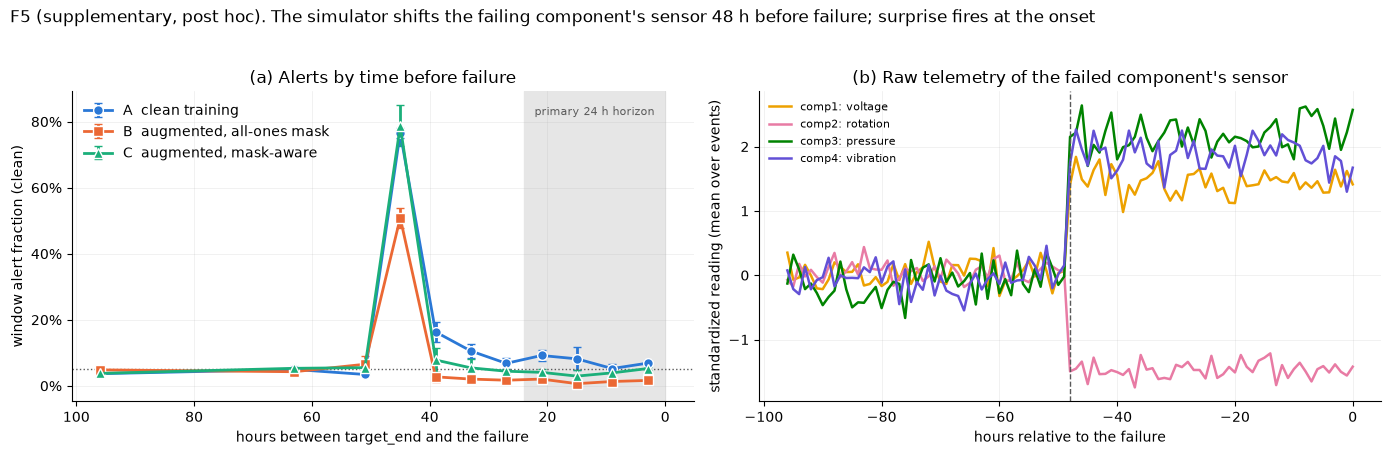

Logged as a post-hoc addendum in results/stage5/protocol_manifest.json


In [13]:
from datetime import datetime, timezone

# 1. Alert fraction by hours to the next failure episode of the same machine.
nxt = pd.merge_asof(eval_meta[["sample_id", "machine_id", "target_end"]].sort_values("target_end"),
                    episodes[["machine_id", "failure_time"]].assign(failure_time=lambda d: pd.to_datetime(d["failure_time"])).sort_values("failure_time"),
                    left_on="target_end", right_on="failure_time", by="machine_id", direction="forward", allow_exact_matches=False)
hours_to_failure = pd.Series(((nxt["failure_time"] - nxt["target_end"]) / H).to_numpy(), index=nxt["sample_id"]).reindex(eval_ds.sample_id.numpy()).to_numpy()
LEAD_BINS = [0, 6, 12, 18, 24, 30, 36, 42, 48, 54, 72, 120, np.inf]
lead_bin = pd.cut(hours_to_failure, LEAD_BINS)
prof = pd.DataFrame([{"model": m, "seed": s, "hours before failure": str(b), "alert fraction": FLAGS[(m, s, "clean")][lead_bin == b].mean(),
                      "windows": int((lead_bin == b).sum())} for m in MODELS for s in SEEDS for b in lead_bin.categories])
lead_profile = prof.groupby(["hours before failure", "model"], sort=False)["alert fraction"].agg(lambda v: pm(v, "{:.3f}")).unstack()
lead_profile["windows"] = prof.groupby("hours before failure", sort=False)["windows"].first()
print("Clean test window alert fraction by hours between target_end and the next failure (mean ± SD over seeds)")
display(lead_profile)

# 2. Raw standardized telemetry of every test failure event, -96 h ... 0 h.
raw_std = raw.copy()
raw_std[SENSORS] = scaler.transform(raw_std[SENSORS])
raw_std = raw_std.set_index(["machine_id", "datetime"]).sort_index()
ev_rows = []
for ev in events.itertuples():
    seg = raw_std.loc[(ev.machine_id, ev.datetime - pd.Timedelta(hours=96)):(ev.machine_id, ev.datetime)].reset_index()
    seg["h"] = (seg["datetime"] - ev.datetime) / H
    ev_rows.append(seg.assign(component=ev.components.split(",")[0]))
around = pd.concat(ev_rows, ignore_index=True)
shift = around[(around["h"] >= -48) & (around["h"] < 0)].groupby("component")[SENSORS].mean() - \
        around[around["h"] < -54].groupby("component")[SENSORS].mean()
print("Mean standardized shift (last 48 h before failure minus 54-96 h before), by first failed component")
display(shift.round(2))
COMPONENT_SENSOR = shift.abs().idxmax(axis=1).to_dict()
print("Sensor with the largest shift per component:", COMPONENT_SENSOR)

# 3. 48 h detection by first failed component.
comp_of = episodes.set_index("episode")["components"].str.split(",").str[0]
by_comp = []
for m in MODELS:
    for s in SEEDS:
        det = detect_episodes(eval_windows, episodes, FLAGS[(m, s, "clean")], H_SECONDARY)
        det = det[det["eligible"]].assign(component=lambda d: d["episode"].map(comp_of))
        by_comp.append(det.groupby("component")["detected"].mean().rename(f"{m} seed {s}"))
by_component = pd.concat(by_comp, axis=1)
print("48 h episode recall by first failed component (clean)")
display(by_component.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
mid = [3, 9, 15, 21, 27, 33, 39, 45, 51, 63, 96]
for m in MODELS:
    vals = np.array([[FLAGS[(m, s, "clean")][lead_bin == b].mean() for b in lead_bin.categories[:len(mid)]] for s in SEEDS])
    axes[0].errorbar(mid, vals.mean(0), yerr=vals.std(0, ddof=1), color=MODEL_COLORS[m], marker=MODEL_MARKERS[m], lw=2, ms=7,
                     capsize=3, mec="white", label=MODEL_LABELS[m])
axes[0].axhline(1 - PCT / 100, color="0.35", lw=1, ls=":")
axes[0].axvspan(0, H_PRIMARY, color="0.9", zorder=0)
axes[0].text(12, axes[0].get_ylim()[1] * 0.95, "primary 24 h horizon", ha="center", va="top", fontsize=8, color="0.35")
axes[0].invert_xaxis()
axes[0].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[0].set(xlabel="hours between target_end and the failure", ylabel="window alert fraction (clean)",
            title="(a) Alerts by time before failure")
axes[0].legend(frameon=False, loc="upper left")
COMPONENT_COLORS = dict(zip(sorted(COMPONENT_SENSOR), ["#eda100", "#e87ba4", "#008300", "#6250d6"]))  # slots 4-7: never model colours
for comp, sensor in sorted(COMPONENT_SENSOR.items()):
    sub = around[around["component"] == comp].groupby("h")[sensor].mean()
    axes[1].plot(sub.index, sub.values, lw=1.8, color=COMPONENT_COLORS[comp], label=f"{comp}: {sensor}")
axes[1].axvline(-48, color="0.35", lw=1, ls="--")
axes[1].set(xlabel="hours relative to the failure", ylabel="standardized reading (mean over events)",
            title="(b) Raw telemetry of the failed component's sensor")
axes[1].legend(frameon=False, fontsize=8, loc="upper left")
fig.suptitle("F5 (supplementary, post hoc). The simulator shifts the failing component's sensor 48 h before failure; "
             "surprise fires at the onset", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(FIGURES_DIR / "F5_posthoc_failure_onset.png", dpi=150, bbox_inches="tight")
plt.show()

if not DRY_RUN:
    man = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
    if "post_hoc_analyses" not in man:
        man["post_hoc_analyses"] = [{
            "added": datetime.now(timezone.utc).isoformat(timespec="seconds"), "test_results_inspected_before": True,
            "protocol_changed": False, "section": "9.8 post-hoc analysis",
            "description": "alert fraction by hours before failure; raw telemetry around failures; 48 h recall by component; figure F5"}]
        MANIFEST_PATH.write_text(json.dumps(man, indent=2), encoding="utf-8")
    print("Logged as a post-hoc addendum in", rel(MANIFEST_PATH))

In [14]:
prim_ev = event_metrics.query("setting == 'primary' and scenario == 'clean'")
lift40 = event_metrics.query("setting == 'primary' and scenario == 'independent_40'")
lines = [
    "# Stage 5 limitations and sensitivity",
    "",
    f"Generated by notebooks/05_final_evaluation.ipynb; protocol sha256 `{S5_SHA}`.",
    "",
    "## Implicit missingness cue (zero fill)",
    f"- Exact zeros among standardized context readings: train {zero_counts['train']['exact zeros']:,} of {zero_counts['train']['readings']:,}, "
    f"validation {zero_counts['val']['exact zeros']:,} of {zero_counts['val']['readings']:,}.",
    "- A zero-filled reading is therefore, in principle, an unambiguous missingness indicator even for Model B. "
    "The B vs C comparison tests whether an EXPLICIT mask helps beyond zero-fill augmentation with this cue present; "
    "it does not show that availability information is useless in general (e.g. with mean/forward-fill imputation or "
    "readings that can genuinely be zero). An MLP may still find the exact-zero cue hard to use, because 0 is the "
    "training mean and lies in the bulk of the data.",
    "",
    "## Model C seed variability",
    "- Model C seed 33 is the epoch-3 checkpoint selected by the frozen Stage 4 rule; its effective rank (16.7) is close "
    "to the non-collapse threshold of 16. All three seeds remain in the primary results.",
    f"- Supplementary seeds 11/22 only: " + "; ".join(f"{r['contrast']}: D_B - D_C = {r['D_B - D_C (pp)']:.3f} pp, {r['95% CI (pp)']}"
                                                   for _, r in supplementary[supplementary['seeds'].str.startswith('seeds')].iterrows()) + ".",
    "",
    "## Robustness vs responsiveness",
    "- Pre-failure alert lift over proxy-normal windows (clean, 24 h horizon): " + "; ".join(
        f"{m} {pm(prim_ev.query('model == @m')['lift_vs_proxy_normal'], '{:.2f}')}x" for m in MODELS) + ".",
    "- Under 40% dropout: " + "; ".join(
        f"{m} {pm(lift40.query('model == @m')['lift_vs_proxy_normal'], '{:.2f}')}x" for m in MODELS) + ".",
    "",
    "## Simulator artifact behind the failure-warning numbers (post hoc)",
    "- In the Azure simulator, the sensor of the failing component (" + ", ".join(f"{c} -> {s}" for c, s in sorted(COMPONENT_SENSOR.items())) +
    ") shifts abruptly about 48 h before each failure and stays shifted until it.",
    "- Next-latent surprise fires at the ONSET (target blocks ending 42-48 h before failure: alert fraction " +
    ", ".join(f"{m} {lead_profile.loc[str(pd.Interval(42.0, 48.0)), m]}" for m in MODELS) +
    "); once the shift is in the history it is predicted, so the primary 24 h horizon sees little.",
    "- 48 h (secondary) recall therefore reflects detection of an injected step, not realistic gradual degradation; "
    "do not generalize it to physical machines.",
    "- Model B detects far fewer onsets (48 h recall " + pm(event_metrics.query("setting == 'secondary horizon' and model == 'B'")["recall"], "{:.2f}") +
    " vs A " + pm(event_metrics.query("setting == 'secondary horizon' and model == 'A'")["recall"], "{:.2f}") +
    ", C " + pm(event_metrics.query("setting == 'secondary horizon' and model == 'C'")["recall"], "{:.2f}") +
    "): part of its robustness to dropout is lower sensitivity to genuine distribution shifts.",
    "",
    "## Leakage and protocol audit",
    "- Chronological partitions; every train/validation window ends before the first test window starts; sample ids disjoint.",
    "- Scaler fitted on exactly the training-period rows; test windows reproduced from raw telemetry with it.",
    "- No failure, maintenance or error labels enter the encoder or predictor; labels only select evaluation windows/events.",
    "- Thresholds: 95th percentile of clean VALIDATION surprise per model and seed, identical to Stage 4; never refitted on test.",
    "- Checkpoints: the nine frozen Stage 3/4 selections; parameters verified unchanged after scoring; no optimizer constructed.",
    "- Protocol frozen (configs/stage5.yaml, sha256 in results/stage5/protocol_manifest.json) before any test prediction.",
    "- Caveat: Stage 1 exploratory, failure-centred plots covered the full period including test.",
    "",
    "## Domain and design limitations",
    "- Azure PdM telemetry is simulated; no verification on physical industrial machines.",
    "- Dropouts are synthetic and imposed only on the historical context; prediction targets are always clean and complete.",
    "- Three training seeds; machine-bootstrap intervals cover machine variation for fixed checkpoints, not new seeds, datasets or sites.",
    "- Failure analysis is exploratory: few episodes, 6 h resolution, scores available only after target_end; alerts are not diagnoses.",
]
(RESULTS_DIR / "limitations_and_sensitivity.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
print(f"Wrote {rel(RESULTS_DIR / 'limitations_and_sensitivity.md')}")

Wrote results/stage5/limitations_and_sensitivity.md


## 9.9 Figures, tables, evidence ledger and acceptance gate

| Figure | Content | Guardrail |
|---|---|---|
| **F1** | test relative MSE degradation at 0/10/20/40% dropout | no raw-MSE ranking across models |
| **F2** | excess alert fraction under dropout, all and proxy-normal windows | window fractions, not confirmed false alarms |
| **F3** | stress patterns: paired differences with machine-bootstrap intervals | actual removed shares in the labels |
| **F4** | 24 h failure-episode recall vs chance, and pre-failure alert lift | exploratory; alarm time = `target_end` |

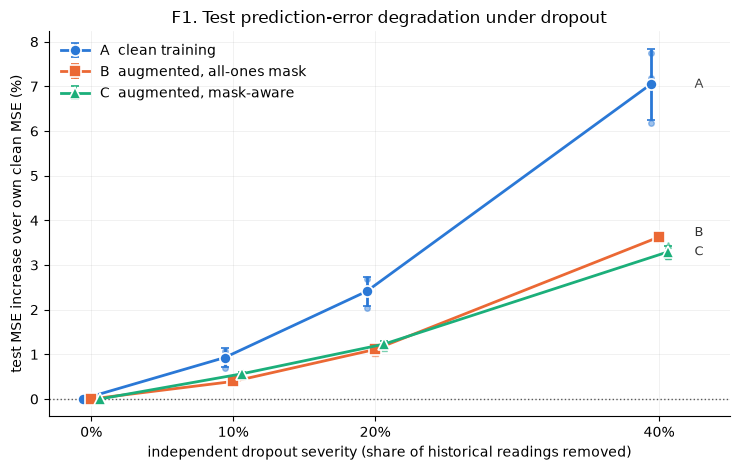

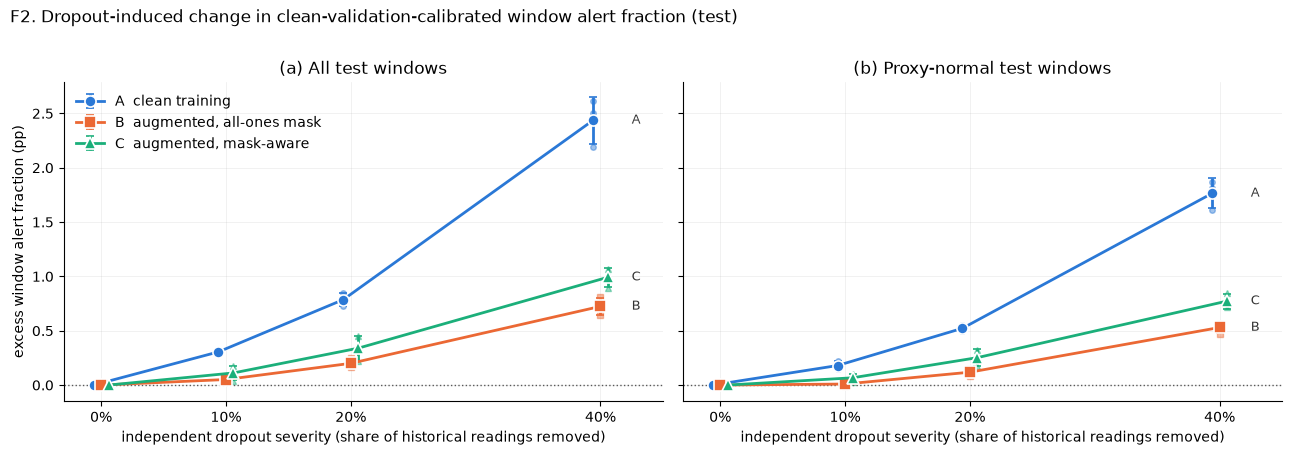

In [15]:
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
x = [100 * SEVERITY[n] for n in ["clean", *INDEPENDENT]]


def severity_panel(ax, metric, scale):
    ends = {}
    for m in MODELS:
        vals = np.array([[per_seed.query("model == @m and seed == @s and scenario == @n")[metric].item() * scale
                          for n in ["clean", *INDEPENDENT]] for s in SEEDS])
        dx = {"A": -0.6, "B": 0.0, "C": 0.6}[m]
        ax.errorbar(np.array(x) + dx, vals.mean(0), yerr=vals.std(0, ddof=1), color=MODEL_COLORS[m], marker=MODEL_MARKERS[m],
                    ms=8, lw=2, capsize=3, mec="white", mew=1.2, label=MODEL_LABELS[m], zorder=3)
        for row in vals:
            ax.plot(np.array(x) + dx, row, MODEL_MARKERS[m], ms=4, color=MODEL_COLORS[m], alpha=0.45, zorder=2)
        ends[m] = vals.mean(0)[-1]
    lo, hi = ax.get_ylim()
    placed = []
    for m in sorted(ends, key=ends.get):
        y = ends[m] if not placed else max(ends[m], placed[-1] + 0.05 * (hi - lo))
        placed.append(y)
        ax.text(x[-1] + 2.5, y, m, va="center", fontsize=9, color="0.2")
    ax.set_xlim(x[0] - 3, x[-1] + 5)
    ax.set_xticks(x, [f"{v:.0f}%" for v in x])
    ax.set_xlabel("independent dropout severity (share of historical readings removed)")


fig, ax = plt.subplots(figsize=(7.5, 4.8))
severity_panel(ax, "D", 100)
ax.axhline(0, color="0.35", lw=1, ls=":")
ax.set(ylabel="test MSE increase over own clean MSE (%)", title="F1. Test prediction-error degradation under dropout")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "F1_dropout_robustness.png", dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
severity_panel(axes[0], "excess_alert_pp", 1)
severity_panel(axes[1], "proxy_normal_excess_pp", 1)
for ax, title in zip(axes, ["(a) All test windows", "(b) Proxy-normal test windows"]):
    ax.axhline(0, color="0.35", lw=1, ls=":")
    ax.set_title(title)
axes[0].set_ylabel("excess window alert fraction (pp)")
axes[0].legend(frameon=False, loc="upper left")
fig.suptitle("F2. Dropout-induced change in clean-validation-calibrated window alert fraction (test)", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.97))
fig.savefig(FIGURES_DIR / "F2_excess_alerts.png", dpi=150, bbox_inches="tight")
plt.show()

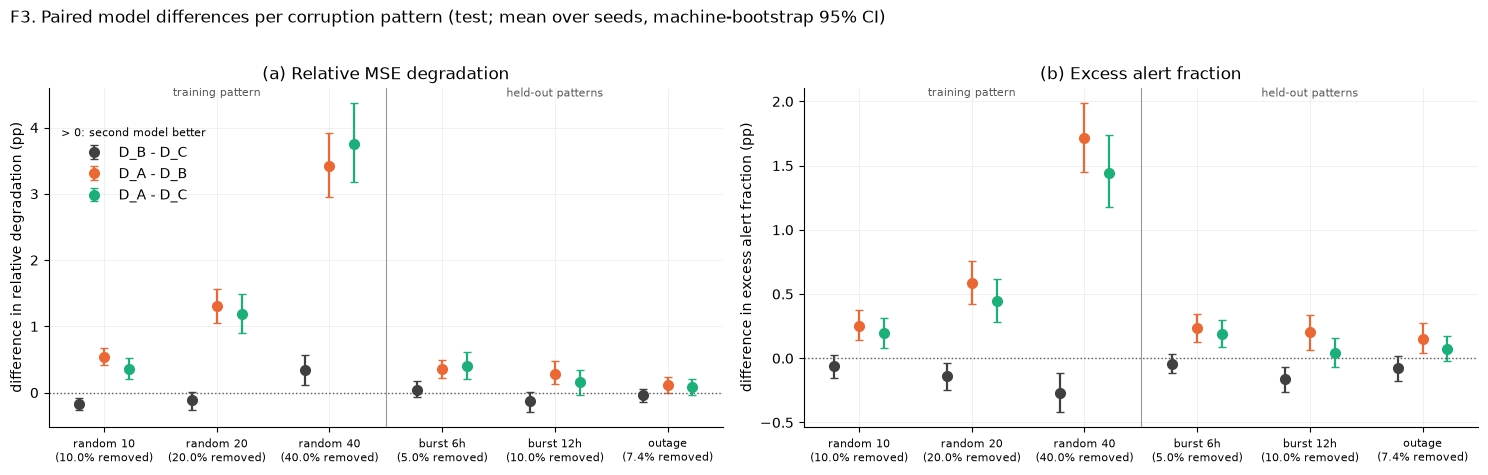

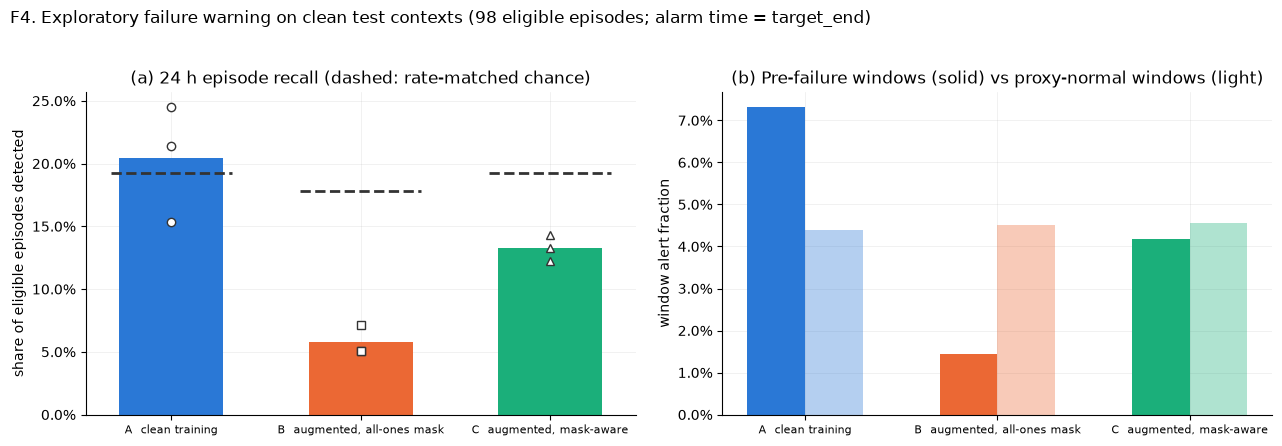

In [16]:
removed = corruption_manifest["removed_share"]
labels = {n: f"{n.replace('independent_', 'random ').replace('burst_', 'burst ').replace('_', ' ')}\n({100 * removed[n]:.1f}% removed)" for n in SCENARIOS[1:]}
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=False)
for ax, metric, ylabel, title in ((axes[0], "D", "difference in relative degradation (pp)", "(a) Relative MSE degradation"),
                                  (axes[1], "excess_alert_pp", "difference in excess alert fraction (pp)", "(b) Excess alert fraction")):
    pos = np.arange(len(SCENARIOS[1:]))
    for j, (first, second) in enumerate(COMPARISONS):
        comp = f"{first} - {second}"
        sub = intervals.query("comparison == @comp and metric == @metric").set_index("contrast").loc[SCENARIOS[1:]]
        sc = 100 if metric == "D" else 1
        est, lo, hi = sub["estimate_mean_over_seeds"] * sc, sub["ci_low"] * sc, sub["ci_high"] * sc
        color = {"B - C": "0.25", "A - B": MODEL_COLORS["B"], "A - C": MODEL_COLORS["C"]}[f"{first} - {second}"]
        ax.errorbar(pos + (j - 1) * 0.22, est, yerr=[est - lo, hi - est], fmt="o", color=color, ms=7, capsize=3, lw=1.6,
                    label=f"D_{first} - D_{second}" if metric == "D" else f"{first} - {second}")
    ax.axhline(0, color="0.35", lw=1, ls=":")
    ax.axvline(2.5, color="0.6", lw=0.8)
    ax.text(1, ax.get_ylim()[1], "training pattern", ha="center", va="top", fontsize=8, color="0.35")
    ax.text(4, ax.get_ylim()[1], "held-out patterns", ha="center", va="top", fontsize=8, color="0.35")
    ax.set_xticks(pos, [labels[n] for n in SCENARIOS[1:]], fontsize=8)
    ax.set(ylabel=ylabel, title=title)
axes[0].legend(frameon=False, loc="upper left", bbox_to_anchor=(0, 0.92), title="> 0: second model better", title_fontsize=8)
fig.suptitle("F3. Paired model differences per corruption pattern (test; mean over seeds, machine-bootstrap 95% CI)", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.savefig(FIGURES_DIR / "F3_stress_patterns.png", dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
pos = np.arange(len(MODELS))
for i, m in enumerate(MODELS):
    q = prim_ev.query("model == @m")
    axes[0].bar(i, q["recall"].mean(), 0.55, color=MODEL_COLORS[m], zorder=2)
    axes[0].plot([i] * len(q), q["recall"], MODEL_MARKERS[m], ms=6, mfc="white", mec="0.2", zorder=3)
    axes[0].plot([i - 0.32, i + 0.32], [q["chance_recall"].mean()] * 2, color="0.2", lw=2, ls="--", zorder=4)
    axes[1].bar(i - 0.15, q["prefailure_window_alert_rate"].mean(), 0.3, color=MODEL_COLORS[m], zorder=2)
    axes[1].bar(i + 0.15, q["proxy_normal_alert_rate"].mean(), 0.3, color=MODEL_COLORS[m], alpha=0.35, zorder=2)
axes[0].set_xticks(pos, [MODEL_LABELS[m] for m in MODELS], fontsize=8)
axes[0].set(ylabel="share of eligible episodes detected", title=f"(a) {H_PRIMARY} h episode recall (dashed: rate-matched chance)")
axes[0].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[1].set_xticks(pos, [MODEL_LABELS[m] for m in MODELS], fontsize=8)
axes[1].set(ylabel="window alert fraction", title="(b) Pre-failure windows (solid) vs proxy-normal windows (light)")
axes[1].yaxis.set_major_formatter(PercentFormatter(1.0))
fig.suptitle(f"F4. Exploratory failure warning on clean test contexts ({int(prim_ev['eligible_episodes'].iloc[0])} eligible episodes; "
             "alarm time = target_end)", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(FIGURES_DIR / "F4_failure_warning.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
def ci_txt(comp, contrast, metric, scale):
    r = D40.loc[(comp, contrast, metric)]
    return (f"{scale * r['estimate_mean_over_seeds']:+.2f} [{scale * r['ci_low']:+.2f}, {scale * r['ci_high']:+.2f}] "
            f"({r['seeds_positive']}/{len(SEEDS)} seeds > 0)")


t1 = {}
for m in MODELS:
    q = per_seed.query("model == @m")
    row = {"clean MSE / target variance": pm(q.query("scenario == 'clean'")["clean_mse_normalized"], "{:.3f}")}
    for n in INDEPENDENT:
        row[f"D at {100 * SEVERITY[n]:.0f}% (%)"] = pm(q.query("scenario == @n")["D"] * 100, "{:.2f}")
    for n in HELD_OUT:
        row[f"D {n} (%)"] = pm(q.query("scenario == @n")["D"] * 100, "{:.2f}")
    t1[m] = row
T1 = pd.DataFrame(t1)
for comp in ("B - C", "A - B", "A - C"):
    T1.loc[f"{comp}: D difference at 40% (pp)", "paired effect"] = ci_txt(comp, "independent_40", "D", 100)
    T1.loc[f"{comp}: D difference, 10/20/40 trajectory (pp)", "paired effect"] = ci_txt(comp, "trajectory_10_20_40", "D", 100)
T1.to_csv(RESULTS_DIR / "T1_test_performance.csv")

t2 = {}
for m in MODELS:
    q = alerts.query("model == @m")
    row = {"clean test alert fraction": pm(q.query("scenario == 'clean'")["alert_rate"] * 100, "{:.2f}") + " %",
           "proxy-normal clean alert fraction": pm(q.query("scenario == 'clean'")["proxy_normal_alert_rate"] * 100, "{:.2f}") + " %",
           "incidents per machine-day (clean)": pm(q.query("scenario == 'clean'")["incidents_per_machine_day"], "{:.4f}")}
    for n in SCENARIOS[1:]:
        row[f"excess alerts {n} (pp)"] = pm(q.query("scenario == @n")["excess_alert_pp"], "{:+.2f}")
        row[f"proxy-normal excess {n} (pp)"] = pm(q.query("scenario == @n")["proxy_normal_excess_pp"], "{:+.2f}")
    t2[m] = row
T2 = pd.DataFrame(t2)
T2.to_csv(RESULTS_DIR / "T2_test_alerts.csv")

table_b4 = pd.read_csv(PROJECT_ROOT / "results" / "stage4_table_b.csv")
T3 = table_b4[["model", "seed", "selected epoch", "selection objective", "val SIGReg", "effective rank", "min latent std",
               "target latent variance (trace)", "parameters"]].copy()
T3["test clean target variance (mean per dim)"] = [TARGET_VAR[(m, s)] for m, s in zip(T3["model"], T3["seed"])]
T3.to_csv(RESULTS_DIR / "T3_checkpoints.csv", index=False)

T4 = event_metrics.query("setting == 'primary' and scenario == 'clean'").groupby("model").agg(
    eligible_episodes=("eligible_episodes", "first"), recall=("recall", lambda v: pm(v, "{:.3f}")),
    chance_recall=("chance_recall", lambda v: pm(v, "{:.3f}")), lead_median_h=("lead_median_h", lambda v: pm(v, "{:.1f}")),
    prefailure_alert=("prefailure_window_alert_rate", lambda v: pm(v, "{:.3f}")),
    proxy_normal_alert=("proxy_normal_alert_rate", lambda v: pm(v, "{:.3f}")),
    incidents_per_machine_day=("incidents_per_machine_day", lambda v: pm(v, "{:.4f}")))
T4.to_csv(RESULTS_DIR / "T4_failure_events.csv")

for name, table in (("T1. Final test performance (mean ± SD over seeds; paired effects: mean over seeds [machine-bootstrap 95% CI])", T1),
                    ("T2. Test alerts with fixed clean-validation thresholds", T2),
                    ("T3. Frozen checkpoints (Stage 4 diagnostics, unchanged)", T3),
                    ("T4. Exploratory failure-episode warning (clean, 24 h, alarm at target_end)", T4)):
    print(name)
    display(table)

T1. Final test performance (mean ± SD over seeds; paired effects: mean over seeds [machine-bootstrap 95% CI])


,A,B,C,paired effect
clean MSE / target variance,0.842 ± 0.002,0.846 ± 0.006,0.830 ± 0.036,NaN
D at 10% (%),0.93 ± 0.21,0.39 ± 0.02,0.56 ± 0.05,NaN
D at 20% (%),2.41 ± 0.33,1.11 ± 0.07,1.23 ± 0.07,NaN
D at 40% (%),7.04 ± 0.80,3.63 ± 0.04,3.29 ± 0.14,NaN
D burst_6h (%),1.05 ± 0.10,0.70 ± 0.04,0.65 ± 0.05,NaN
D burst_12h (%),1.96 ± 0.06,1.67 ± 0.04,1.80 ± 0.22,NaN
D outage (%),1.73 ± 0.08,1.61 ± 0.02,1.65 ± 0.33,NaN
B - C: D difference at 40% (pp),NaN,NaN,NaN,"+0.34 [+0.11, +0.57] (3/3 seeds > 0)"
"B - C: D difference, 10/20/40 trajectory (pp)",NaN,NaN,NaN,"+0.02 [-0.09, +0.12] (2/3 seeds > 0)"
A - B: D difference at 40% (pp),NaN,NaN,NaN,"+3.42 [+2.95, +3.92] (3/3 seeds > 0)"


T2. Test alerts with fixed clean-validation thresholds


,A,B,C
clean test alert fraction,5.21 ± 0.12 %,4.78 ± 0.05 %,5.21 ± 0.01 %
proxy-normal clean alert fraction,4.39 ± 0.13 %,4.51 ± 0.06 %,4.56 ± 0.13 %
incidents per machine-day (clean),0.1610 ± 0.0049,0.1661 ± 0.0011,0.1715 ± 0.0010
excess alerts independent_10 (pp),+0.31 ± +0.02,+0.05 ± +0.01,+0.11 ± +0.07
proxy-normal excess independent_10 (pp),+0.18 ± +0.04,+0.01 ± +0.03,+0.07 ± +0.04
excess alerts independent_20 (pp),+0.79 ± +0.06,+0.20 ± +0.04,+0.34 ± +0.12
proxy-normal excess independent_20 (pp),+0.52 ± +0.03,+0.12 ± +0.03,+0.25 ± +0.08
excess alerts independent_40 (pp),+2.44 ± +0.22,+0.72 ± +0.08,+0.99 ± +0.09
proxy-normal excess independent_40 (pp),+1.76 ± +0.14,+0.53 ± +0.05,+0.77 ± +0.07
excess alerts burst_6h (pp),+0.41 ± +0.05,+0.18 ± +0.01,+0.22 ± +0.07


T3. Frozen checkpoints (Stage 4 diagnostics, unchanged)


,model,seed,selected epoch,selection objective,val SIGReg,effective rank,min latent std,target latent variance (trace),parameters,test clean target variance (mean per dim)
0,A,11,16,0.906842,2.250506,28.867255,0.803104,25.616247,36224,0.812544
1,A,22,20,0.910797,2.392974,28.740560,0.813413,25.256477,36224,0.799535
2,A,33,21,0.910159,2.333984,28.712810,0.796214,25.597559,36224,0.809436
3,B,11,26,0.885382,3.493465,29.304083,0.797611,23.053235,36224,0.718190
4,B,22,21,0.884837,3.910566,29.494294,0.746006,21.623230,36224,0.685255
5,B,33,24,0.887051,3.817380,28.887504,0.758034,22.221635,36224,0.707237
6,C,11,26,1.141387,7.737885,25.168778,0.619399,16.410973,36224,0.521499
7,C,22,22,1.144475,7.956702,23.598781,0.590748,16.228787,36224,0.512101
8,C,33,3,1.161177,6.209019,16.656726,0.560927,19.798517,36224,0.624061


T4. Exploratory failure-episode warning (clean, 24 h, alarm at target_end)


,eligible_episodes,recall,chance_recall,lead_median_h,prefailure_alert,proxy_normal_alert,incidents_per_machine_day
model,,,,,,,
A,98,0.204 ± 0.047,0.193 ± 0.004,13.0 ± 0.0,0.073 ± 0.016,0.044 ± 0.001,0.1610 ± 0.0049
B,98,0.058 ± 0.012,0.178 ± 0.002,9.0 ± 3.5,0.014 ± 0.003,0.045 ± 0.001,0.1661 ± 0.0011
C,98,0.133 ± 0.010,0.193 ± 0.000,11.0 ± 3.5,0.042 ± 0.004,0.046 ± 0.001,0.1715 ± 0.0010


In [18]:
# Evidence ledger: the frozen claim rules of configs/stage5.yaml applied mechanically.
def rule_D(comp, contrast):
    r = D40.loc[(comp, contrast, "D")]
    return bool(r["seeds_positive"] == len(SEEDS) and r["ci_low"] > 0)


aug_ok = rule_D("A - B", "independent_40") and rule_D("A - C", "independent_40")
alert_bc = D40.loc[("B - C", "independent_40", "excess_alert_pp")]
mask_ok = (rule_D("B - C", "independent_40") and rule_D("B - C", "trajectory_10_20_40")
           and not (alert_bc["ci_high"] < 0))
warn = {}
for m in MODELS:
    q = prim_ev.query("model == @m")
    warn[m] = bool((q["recall"] > q["chance_recall"]).all() and (q["prefailure_window_alert_rate"] > q["proxy_normal_alert_rate"]).all())
n_eligible = int(prim_ev["eligible_episodes"].iloc[0])
warn_numeric = n_eligible >= 30
sec_ev = event_metrics.query("setting == 'secondary horizon' and scenario == 'clean'")

claims = [
    ("Corruption augmentation improves robustness to historical dropout",
     f"D_A - D_B at 40%: {ci_txt('A - B', 'independent_40', 'D', 100)} pp; D_A - D_C: {ci_txt('A - C', 'independent_40', 'D', 100)} pp; "
     f"excess alerts A - B at 40%: {ci_txt('A - B', 'independent_40', 'excess_alert_pp', 1)} pp",
     "test", "Yes" if aug_ok else "No (rule not met)", "Synthetic missingness on simulated telemetry; clean targets; three seeds"),
    ("An explicit availability mask improves on augmentation (C better than B)",
     f"D_B - D_C at 40%: {ci_txt('B - C', 'independent_40', 'D', 100)} pp; trajectory: {ci_txt('B - C', 'trajectory_10_20_40', 'D', 100)} pp; "
     f"excess alerts B - C at 40%: {ci_txt('B - C', 'independent_40', 'excess_alert_pp', 1)} pp",
     "test", "Yes" if mask_ok else "No (rule not met)", "Zero fill is itself an exact missingness cue (no natural exact zeros); C seed 33 is an epoch-3 checkpoint"),
    ("The model warns of failures early (24 h)",
     "; ".join(f"{m}: recall {pm(prim_ev.query('model == @m')['recall'], '{:.2f}')} vs chance {pm(prim_ev.query('model == @m')['chance_recall'], '{:.2f}')}, "
               f"lift {pm(prim_ev.query('model == @m')['lift_vs_proxy_normal'], '{:.2f}')}x" for m in MODELS) + f"; {n_eligible} eligible episodes",
     "test", ("Exploratory association only for " + ", ".join(m for m in MODELS if warn[m]) + ("" if warn_numeric else "; no numerical claim (< 30 episodes)"))
             if any(warn.values()) else "No (rule not met)",
     "Score available only after target_end; 6 h resolution; alerts are not diagnoses; few episodes"),
    ("Surprise flags the onset of pre-failure shifts (secondary 48 h horizon)",
     "; ".join(f"{m}: recall {pm(sec_ev.query('model == @m')['recall'], '{:.2f}')} vs chance {pm(sec_ev.query('model == @m')['chance_recall'], '{:.2f}')}"
               for m in MODELS) + f"; median lead {sec_ev['lead_median_h'].median():.0f} h; {int(sec_ev['eligible_episodes'].iloc[0])} eligible episodes",
     "test", "Only as a secondary, exploratory observation (no frozen claim rule covers 48 h)",
     "Post hoc: the simulator injects a step in the failing component's sensor 48 h before failure; not realistic degradation"),
    ("SIGReg-trained representations are non-collapsed",
     "Stage 3/4 predefined criteria met by all nine selected checkpoints (effective rank >= 16, every latent std >= 0.1)",
     "validation", "Yes, as non-collapse by the predefined criteria",
     "Model C has lower effective rank (25.2, 23.6, 16.7); no physical semantics claimed"),
]
ledger = pd.DataFrame(claims, columns=["Proposed claim", "Quantitative evidence", "Partition", "Can we state it?", "Required limitation"])
display(ledger)
md_lines = ["# Stage 5 abstract evidence ledger", "",
            f"Claim rules are frozen in `configs/stage5.yaml` (sha256 `{S5_SHA}`) and applied mechanically in notebook 05, Section 9.9.", "",
            "| " + " | ".join(ledger.columns) + " |", "|" + "---|" * len(ledger.columns)]
md_lines += ["| " + " | ".join(str(v).replace("|", "/") for v in row) + " |" for row in ledger.itertuples(index=False)]
(RESULTS_DIR / "abstract_claims.md").write_text("\n".join(md_lines) + "\n", encoding="utf-8")
print(f"Wrote {rel(RESULTS_DIR / 'abstract_claims.md')}")

,Proposed claim,Quantitative evidence,Partition,Can we state it?,Required limitation
0,Corruption augmentation improves robustness to...,"D_A - D_B at 40%: +3.42 [+2.95, +3.92] (3/3 se...",test,Yes,Synthetic missingness on simulated telemetry; ...
1,An explicit availability mask improves on augm...,"D_B - D_C at 40%: +0.34 [+0.11, +0.57] (3/3 se...",test,No (rule not met),Zero fill is itself an exact missingness cue (...
2,The model warns of failures early (24 h),"A: recall 0.20 ± 0.05 vs chance 0.19 ± 0.00, l...",test,No (rule not met),Score available only after target_end; 6 h res...
3,Surprise flags the onset of pre-failure shifts...,A: recall 0.93 ± 0.02 vs chance 0.35 ± 0.01; B...,test,"Only as a secondary, exploratory observation (...",Post hoc: the simulator injects a step in the ...
4,SIGReg-trained representations are non-collapsed,Stage 3/4 predefined criteria met by all nine ...,validation,"Yes, as non-collapse by the predefined criteria","Model C has lower effective rank (25.2, 23.6, ..."


Wrote results/stage5/abstract_claims.md


In [19]:
summary5 = {
    "stage": 5, "evaluation_only": True, "partition": EVAL_PARTITION, "calibration_partition": CAL_PARTITION,
    "protocol": {"config": rel(S5_PATH), "sha256": S5_SHA, "frozen_at": manifest.get("frozen_at")},
    "checkpoints": checkpoint_manifest[["model", "seed", "checkpoint", "selected_epoch", "file_sha256"]].to_dict(orient="records"),
    "weights_unchanged_after_scoring": weights_unchanged,
    "scenarios": corruption_manifest[["removed_share", "windows_affected", "schedule_sha256"]].to_dict(orient="index"),
    "robustness": {m: {n: {k: mean_std(per_seed.query("model == @m and scenario == @n")[k])
                           for k in ("clean_mse", "clean_mse_normalized", "D", "D_affected", "alert_rate", "excess_alert_pp",
                                     "proxy_normal_alert_rate", "proxy_normal_excess_pp", "incidents_per_machine_day")}
                       for n in SCENARIOS} for m in MODELS},
    "contrasts": intervals.to_dict(orient="records"),
    "heterogeneity_independent_40": heterogeneity,
    "failure_events": {"rows": rows_in_partition, "distinct_events": len(events), "episodes": len(episodes),
                       "eligible_primary": n_eligible,
                       "primary_clean": {m: {k: mean_std(prim_ev.query("model == @m")[k]) for k in
                                             ("recall", "chance_recall", "lead_median_h", "prefailure_window_alert_rate",
                                              "proxy_normal_alert_rate", "lift_vs_proxy_normal", "incidents_per_machine_day")}
                                         for m in MODELS},
                       "secondary_48h_clean": {m: {k: mean_std(sec_ev.query("model == @m")[k]) for k in
                                                   ("recall", "chance_recall", "lead_median_h", "lift_vs_proxy_normal")} for m in MODELS}},
    "post_hoc_not_preregistered": {"alert_fraction_by_hours_before_failure": lead_profile.to_dict(orient="index"),
                                   "component_sensor_shift": COMPONENT_SENSOR, "recall_48h_by_component": by_component.round(4).to_dict()},
    "implicit_zero_cue": zero_counts, "supplementary_seeds_11_22": supplementary.to_dict(orient="records"),
    "claims": ledger.to_dict(orient="records"),
}
save_json(summary5, RESULTS_DIR / "summary.json")

gate = []


def check5(name, condition):
    gate.append((name, bool(condition)))
    print(f"[{'PASS' if condition else 'FAIL'}] {name}")


check5("Protocol frozen before test predictions and verified unchanged (9.1)", DRY_RUN or MANIFEST_PATH.exists())
check5("Nine checkpoints verified; evaluation mode; weights unchanged after scoring (9.2, 9.4)", all(ckpt_checks.values()) and weights_unchanged)
check5("Data, chronology, scaler provenance and Stage 4 regression checks (9.2)", all(data_checks.values()))
check5("Stage 5 protocol tests pass (9.2)", protocol_tests["passed"].all())
check5("Paired, reproducible, overlap-consistent test schedules; targets untouched (9.3)", corruption_manifest[bool_cols].all().all())
check5("All 9 model-seeds x 7 scenarios scored on the same windows; summaries reproduce from saved files (9.4)",
       len(SC) == len(MODELS) * len(SEEDS) * len(SCENARIOS) and reproducible_from_files)
check5("Thresholds from clean validation only, identical to Stage 4, applied unchanged (9.5)", thresholds_ok)
check5("Paired B - C effects, seed spread and machine-bootstrap intervals reported (9.6)", len(intervals) > 0)
check5("Failure-event timing, eligibility and one-credit-per-window audits pass (9.7)", audit_ok)
check5("Evidence ledger written from the frozen claim rules (9.9)", (RESULTS_DIR / "abstract_claims.md").exists())
outputs5 = [RESULTS_DIR / f for f in ("protocol_manifest.json", "integrity_checks.json", "checkpoint_manifest.csv", "corruption_manifest.json",
                                      "per_window_scores.csv.gz", "calibration_scores.csv.gz", "test_robustness_per_seed.csv",
                                      "test_robustness_aggregate.csv", "test_alert_metrics.csv", "test_thresholds.csv",
                                      "test_alert_per_machine.csv", "test_paired_differences.csv", "test_machine_bootstrap_intervals.csv",
                                      "test_seed_consistency.csv", "test_failure_events.csv", "test_failure_event_metrics.csv",
                                      "test_event_matching_audit.csv", "limitations_and_sensitivity.md", "abstract_claims.md", "summary.json",
                                      "T1_test_performance.csv", "T2_test_alerts.csv", "T3_checkpoints.csv", "T4_failure_events.csv")
            if not (DRY_RUN and f == "protocol_manifest.json")]
outputs5 += [FIGURES_DIR / f for f in ("F1_dropout_robustness.png", "F2_excess_alerts.png", "F3_stress_patterns.png", "F4_failure_warning.png",
                                       "F5_posthoc_failure_onset.png")]
check5("All Stage 5 output files written", all(p.exists() for p in outputs5))
print(f"\n{sum(ok for _, ok in gate)}/{len(gate)} Stage 5 gate checks passed")
assert all(ok for _, ok in gate), [n for n, ok in gate if not ok]

[PASS] Protocol frozen before test predictions and verified unchanged (9.1)
[PASS] Nine checkpoints verified; evaluation mode; weights unchanged after scoring (9.2, 9.4)
[PASS] Data, chronology, scaler provenance and Stage 4 regression checks (9.2)
[PASS] Stage 5 protocol tests pass (9.2)
[PASS] Paired, reproducible, overlap-consistent test schedules; targets untouched (9.3)
[PASS] All 9 model-seeds x 7 scenarios scored on the same windows; summaries reproduce from saved files (9.4)
[PASS] Thresholds from clean validation only, identical to Stage 4, applied unchanged (9.5)
[PASS] Paired B - C effects, seed spread and machine-bootstrap intervals reported (9.6)
[PASS] Failure-event timing, eligibility and one-credit-per-window audits pass (9.7)
[PASS] Evidence ledger written from the frozen claim rules (9.9)
[PASS] All Stage 5 output files written

11/11 Stage 5 gate checks passed


## Stage 5 conclusion

All 11 gate checks pass. The protocol was frozen (`configs/stage5.yaml`, sha256 `46c105e4…`) at 2026-10-27 15:22 UTC, before any test prediction.

- **Evaluation only.** The nine frozen checkpoints were scored once, in evaluation mode under `torch.inference_mode()`, and their weights were verified unchanged.
- **Thresholds.** The clean-validation thresholds are identical to Stage 4.
- **Reproducibility.** Every number below is reproduced from `results/stage5/per_window_scores.csv.gz` and the saved embeddings.

All results are on the **test** partition, as mean ± SD over seeds 11, 22, 33; brackets are machine-bootstrap 95% intervals.

| | A clean training | B augmented, all-ones mask | C augmented, mask-aware |
|---|---|---|---|
| clean MSE / own target variance | 0.842 ± 0.002 | 0.846 ± 0.006 | 0.830 ± 0.036 |
| D at 10 / 20 / 40% dropout | 0.93 / 2.41 / **7.04%** | 0.39 / 1.11 / **3.63%** | 0.56 / 1.23 / **3.29%** |
| D burst 6 h / burst 12 h / outage | 1.05 / 1.96 / 1.73% | 0.70 / 1.67 / 1.61% | 0.65 / 1.80 / 1.65% |
| excess alerts at 40% (all / proxy-normal) | +2.44 / +1.76 pp | +0.72 / +0.53 pp | +0.99 / +0.77 pp |
| clean test alert fraction (calibrated at 5% on validation) | 5.21% | 4.78% | 5.21% |

**Answer to the final question**

1. **The test period confirms that corruption augmentation reduces degradation and dropout-induced alerts.**
   - At 40% dropout: $D_A-D_B=+3.42$ pp [2.95, 3.92] and $D_A-D_C=+3.75$ pp [3.17, 4.37], both in 3 of 3 seeds. Over the 10/20/40% trajectory: +1.75 and +1.77 pp.
   - Dropout-induced alerts at 40% fall by about 70% (A − B: +1.71 pp [1.45, 1.99]).
   - The benefit carries over, in smaller form, to the held-out burst and outage patterns.
   - The frozen claim rule is met.
2. **An explicit availability mask does not add a consistent benefit beyond augmentation.**
   - The first primary contrast slightly favours C: at 40% dropout, $D_B-D_C=+0.34$ pp [0.11, 0.57], 3 of 3 seeds, about a tenth of the degradation. This is consistent in direction with validation (+0.15 pp).
   - The second primary contrast, over the 10/20/40% trajectory, is null: +0.02 pp [−0.09, 0.12].
   - At 10% and 20%, B degrades slightly less in every seed (exploratory).
   - C raises *more* dropout-induced alerts than B in every scenario: −0.27 pp [−0.42, −0.11] at 40%, 0 of 3 seeds favour C.
   - The frozen claim rule is **not** met. 64% of machines favour C at 40%; the supplementary seeds 11/22 give the same picture.
3. **Exact zeros never occur in real readings** (0 of 11.8 M train/validation values). Zero-filling therefore already gives B a perfect, if implicit, missingness cue. The B vs C result shows that an explicit mask adds little *in this setting*, not that availability information is useless.

**Failure warning (exploratory)**

- **Counts.** 108 failure rows form 102 distinct events and 102 episodes on 70 machines; 98 are eligible at 24 h.
- **Primary 24 h horizon.** No model meets the frozen rule. Recall is A 0.20, B 0.06, C 0.13, against a rate-matched chance level of about 0.19. Before failures, B and C alert *less* than on proxy-normal windows (lift 0.32× and 0.91×).
- **Secondary 48 h horizon.** Recall is A 0.93, B 0.60, C 0.91, against chance ≈ 0.34, with a median lead of 43 h. The post-hoc analysis (F5) shows why: the simulator shifts the failing component's sensor by 1.5–2.2 SD exactly 48 h before each failure. Surprise fires at the **onset** of the shift, and once the shift is in the history it is predicted. This is detection of an injected step, not realistic degradation, and it must not be presented as early failure prediction.
- **Robust but less responsive.** B detects far fewer onsets than A and C (0.60 vs 0.93/0.91, in every seed and every component). Part of B's robustness to dropout is lower sensitivity to genuine distribution shifts. The mask-aware C keeps A-level onset sensitivity while being about as robust as B in prediction error. This trade-off is secondary and partly post hoc; it is a hypothesis for future work, not a confirmed result.

**Recommended abstract framing.**

- **Principal claim:** corruption augmentation roughly halves the prediction-error degradation and cuts dropout-induced alerts by about 70% under historical sensor dropout.
- **Secondary:** an explicit availability mask did not consistently improve on augmentation (small gain at 40% only, more dropout-induced alerts), although it preserved sensitivity to genuine shifts.
- **Limits:** simulated telemetry, synthetic dropouts on the history only, clean targets, three seeds. No early-failure-prediction claim. See `results/stage5/abstract_claims.md` and `limitations_and_sensitivity.md`.